# Updated Cu K-edge benchmark: audited adsorbate identities and depth sensitivity
This notebook contains the complete current audit, optional record-correction procedure, inventory, spectral preparation, model fitting, nested cross-validation, five requested figure sets, and a short bullet-point interpretation. **Targets are adsorbate identities only.** Molecular counts and geometry descriptors are audited but never used as predictors or prediction targets.

**Setup:** Python 3.11+ with `numpy pandas scipy scikit-learn matplotlib nbformat ipykernel ipython`. Install using `python -m pip install numpy pandas scipy scikit-learn matplotlib nbformat ipykernel ipython`. Exact tested versions are saved in `environment.json`. Run from this notebook folder; update `DATA` and `OUT` below if relocating files. Matching caches avoid refitting. Delete `cache/` after changing feature or model implementations to force fresh fits.

**Outputs:** `figures/01_…` through `05_…` are saved as PNG and PDF. CSV audits, per-species metrics, all feature/model/depth comparisons, fold assignments and held-out predictions are saved alongside the notebook. `ANALYSIS.md` provides the requested simple bullets. New figures use the current cohort only; prior scores are not treated as directly comparable independent tests.

In [1]:
# Complete reproducible analysis; this source is embedded in the notebook.
from pathlib import Path
from collections import Counter,defaultdict
import json,re,hashlib,sys,time,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid
from scipy.fft import dct
from scipy.special import expit
from sklearn.preprocessing import MultiLabelBinarizer,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score,precision_recall_fscore_support,multilabel_confusion_matrix
from IPython.display import display,Markdown
import sklearn,scipy
DATA=Path('/Users/hjia/Downloads/CO2RR')
OUT=Path.cwd()
if OUT.name!='updated_dataset_20261020':OUT=DATA/'CO2RR_ML/updated_dataset_20261020'
FIG=OUT/'figures';FIG.mkdir(exist_ok=True,parents=True)
CACHE=OUT/'cache';CACHE.mkdir(exist_ok=True)
SEED=20261020;LAYERS=[2,3,4,5]
CUT={('C','C'):1.85,('C','O'):1.70,('C','H'):1.30,('H','O'):1.20,('H','H'):.90,('O','O'):1.65}
ALIASES={'2CO_adjacent':['CO'],'H_0p75':['H'],'plain':['clean'],'none':['clean'],'clean':['clean']}
def hash_array(a):return hashlib.sha256(np.round(np.asarray(a,float),10).tobytes()).hexdigest()
def load_structure(p):
    lines=p.read_text().splitlines();scale=float(lines[1]);assert scale>0
    lattice=np.array([list(map(float,s.split())) for s in lines[2:5]])*scale
    names=lines[5].split();counts=list(map(int,lines[6].split()));sp=np.repeat(names,counts)
    i=7
    if lines[i].lower().startswith('s'):i+=1
    direct=lines[i].lower().startswith('d');i+=1
    xyz=np.array([list(map(float,s.split()[:3])) for s in lines[i:i+sum(counts)]])
    assert len(xyz)==sum(counts) and np.isfinite(xyz).all()
    frac=xyz if direct else xyz*scale@np.linalg.inv(lattice)
    cart=frac@lattice;normal=np.cross(lattice[0],lattice[1]);normal/=np.linalg.norm(normal)
    canonical=sorted((str(s),*v) for s,v in zip(sp,np.mod(np.round(frac%1,8),1)))
    sh=hashlib.sha256(json.dumps([np.round(lattice,7).tolist(),canonical]).encode()).hexdigest()
    return dict(species=sp,frac=frac,cart=cart,lattice=lattice,height=cart@normal,hash=sh)
def components(struct,factor=1.):
    sp=struct['species'];idx=np.where(np.isin(sp,['C','O','H']))[0];ss=sp[idx];xyz=struct['frac'][idx]
    delta=xyz[:,None,:]-xyz[None,:,:];delta-=np.rint(delta);dist=np.linalg.norm(delta@struct['lattice'],axis=2)
    adj=np.zeros(dist.shape,bool)
    for i in range(len(idx)):
        for j in range(i):adj[i,j]=adj[j,i]=dist[i,j]<factor*CUT.get(tuple(sorted([ss[i],ss[j]])),0)
    seen=set();result=[]
    for i in range(len(idx)):
        if i in seen:continue
        todo=[i];seen.add(i);group={i}
        while todo:
            a=todo.pop()
            for b in np.where(adj[a])[0]:
                if b not in seen:seen.add(b);group.add(b);todo.append(b)
        co=Counter(ss[list(group)]);c,o,h=(co[x] for x in ['C','O','H'])
        oh=any(adj[a,b] and set([ss[a],ss[b]])=={'H','O'} for a in group for b in group)
        if (c,o,h)==(1,1,1):label='COH' if oh else 'CHO'
        elif (c,o,h)==(1,2,1):label='COOH' if oh else 'OCHO'
        elif (c,o,h)==(2,2,1):label='OCCOH' if oh else 'COCHO'
        else:label={(1,1,0):'CO',(1,2,0):'CO2',(2,2,0):'OCCO',(0,1,1):'OH',(0,0,1):'H',(0,1,0):'O'}.get((c,o,h))
        if label is None:label='unresolved:'+''.join(k+(str(co[k]) if co[k]>1 else '') for k in sorted(co))
        result.append(dict(species=label,formula=dict(co),indices=[int(idx[x]+1) for x in sorted(group)]))
    return result
def molecular_counts(struct):return dict(Counter(c['species'] for c in components(struct)))
def label_set(counts):return tuple(sorted(k for k,v in counts.items() if v>0)) or ('clean',)
def combo(labels):return ' + '.join(labels)
def formula_counts(formula):return Counter({a:int(b or 1) for a,b in re.findall(r'([A-Z][a-z]*)(\d*)',formula)})
def read_record_labels(c):
    if 'adsorbate_counts' in c:return tuple(sorted(k for k,v in c['adsorbate_counts'].items() if int(v)>0)) or ('clean',)
    if c.get('adsorbate_identities'):return tuple(sorted(c['adsorbate_identities']))
    raw=str(c.get('adsorbate_identity',''))
    return tuple(sorted(ALIASES.get(raw,raw.replace('+','_').split('_')))) if raw else None

print('Environment:',sys.version.split()[0], 'numpy',np.__version__,'sklearn',sklearn.__version__)

Environment: 3.11.14 numpy 2.3.5 sklearn 1.8.0


## Check and correct the new count schema
`adsorbate_counts` and `adsorbate_identities` are checked against periodic nonmetal connectivity in the simulated relaxed CONTCAR. COH/CHO and OCCOH/COCHO are separated by H–O versus H–C connectivity. Cutoffs are tested at ±10%. Every geometry entry must match its component formula before its species label can be corrected. Seven regenerated records were backed up and repaired before this run; the default below is read-only and confirms consistency. Set `apply=True` only when intentionally applying newly found corrections; backups precede writes. Measurements are preserved.

In [2]:
# Default read-only on rerun. The seven applied corrections are preserved in record_corrections.json.
def audit_or_correct_count_records(apply=False):
    import tarfile,datetime
    proposals=[];checked=0
    for p in sorted(DATA.rglob('isaac_record_layers.json')):
        if 'CO2RR_ML' in p.relative_to(DATA).parts:continue
        d=json.loads(p.read_text());c=d['sample']['composition']
        if 'adsorbate_counts' not in c:continue
        st=load_structure(p.parent/'layer_5/CONTCAR');co=components(st);counts=dict(Counter(a['species'] for a in co));checked+=1
        assert all(dict(Counter(a['species'] for a in components(st,f)))==counts for f in [.9,1.1]), 'ambiguous component assignment'
        if counts==c['adsorbate_counts'] and sorted(counts)==sorted(c.get('adsorbate_identities',[])):continue
        sites=d['sample']['geometry'].get('adsorption_sites',[]);assert len(sites)==len(co)
        for site,component in zip(sites,co):assert formula_counts(site['formula'])==Counter(component['formula']), 'cannot safely map geometry entries'
        proposals.append((p,d,co,counts))
    if proposals and not apply:raise AssertionError('Count/identity inconsistencies found; inspect and set apply=True to correct with backup')
    if proposals:
        stamp=datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%SZ');backup=OUT/f'record_backup_{stamp}.tar.gz'
        with tarfile.open(backup,'w:gz') as tar:
            for p,d,co,counts in proposals:tar.add(p,arcname=str(p.relative_to(DATA)))
        log=[]
        for p,d,co,counts in proposals:
            before=hashlib.sha256(json.dumps(d['measurement'],sort_keys=True).encode()).hexdigest();old=dict(d['sample']['composition'])
            c=d['sample']['composition'];c['adsorbate_counts']=counts;c['adsorbate_count_total']=sum(counts.values());c['adsorbate_identities']=sorted(counts)
            source=p.parent.parent.parent.parent
            if (source/'POSCAR').is_file():c['poscar_count_crosscheck']='match' if molecular_counts(load_structure(source/'POSCAR'))==counts else 'mismatch'
            for site,component in zip(d['sample']['geometry']['adsorption_sites'],co):site['adsorbate']=component['species']
            d['sample']['material']['notes']+=f' Identity/count correction {stamp}: relaxed molecular connectivity and component formulas verified; spectra unchanged. Backup: {backup}.'
            p.write_text(json.dumps(d,indent=2,ensure_ascii=False)+'\n')
            assert hashlib.sha256(json.dumps(json.loads(p.read_text())['measurement'],sort_keys=True).encode()).hexdigest()==before
            log.append(dict(record=str(p.relative_to(DATA)),before=old,after=c,components=co,measurement_sha256=before))
        (OUT/f'correction_log_{stamp}.json').write_text(json.dumps(log,indent=2))
    print('Modern count-schema records verified:',checked,'new corrections required:',len(proposals))
    return proposals
audit_or_correct_count_records(apply=False)
if (OUT/'record_corrections.json').exists():
    prior_corrections=json.loads((OUT/'record_corrections.json').read_text())
    display(pd.DataFrame([dict(record=r['record'],before=r['before']['adsorbate_counts'],after=r['after']['adsorbate_counts']) for r in prior_corrections['changes']]))



Modern count-schema records verified: 87 new corrections required: 0


,record,before,after
0,CHO/CHO_0p028_Cu_top/XAS/FDMNES/green/isaac_re...,{'CHO': 2},"{'CO': 1, 'H': 1}"
1,CHO/CHO_0p056_interface_Cu/XAS/FDMNES/green/is...,{'CHO': 3},"{'CO': 1, 'CHO': 1, 'H': 1}"
2,CHO/CHO_0p056_interior_Cu/XAS/FDMNES/green/isa...,{'CHO': 3},"{'CO': 1, 'CHO': 1, 'H': 1}"
3,CHO/CHO_0p111_uniform/XAS/FDMNES/green/isaac_r...,{'CHO': 6},"{'CO': 2, 'CHO': 2, 'H': 2}"
4,COCHO/COCHO_0p056_AuCu_interface/XAS/FDMNES/gr...,{'COCHO': 1},{'OCCOH': 1}
5,COCHO/COCHO_0p056_AuCu_interface2/XAS/FDMNES/g...,{'COCHO': 1},{'OCCOH': 1}
6,COCHO/COCHO_0p056_Cu_interface/XAS/FDMNES/gree...,{'COCHO': 3},"{'CO': 2, 'H': 1}"


## Inventory all structures, including unfinished configurations
Discover source folders containing POSCAR/CONTCAR, plus record-associated source folders. Exclude copied calculation-level structures as separate configurations. Use readable CONTCAR, falling back to POSCAR; include the standalone CuO structural reference separately. Deduplicate physical coordinates/atom identities while retaining every alias in CSV.

Count mixtures in mutually exclusive identity-combination groups (CO + H, CHO + CO + H, …), ignoring multiplicity as a new identity class. Also show a nonexclusive per-species presence panel. Source labels can change from POSCAR to CONTCAR after relaxation; that is recorded, not forced to agree.

In [3]:
record_paths=sorted(p for p in DATA.rglob('isaac_record_layers.json') if 'CO2RR_ML' not in p.relative_to(DATA).parts)
record_by_config=defaultdict(list)
for p in record_paths:record_by_config[str(p.parent.parent.parent.parent.relative_to(DATA))].append(p)
source_dirs=set(record_by_config)
for name in ['POSCAR','CONTCAR']:
    for p in DATA.rglob(name):
        if not any(x in p.relative_to(DATA).parts for x in ['XAS','CO2RR_ML','.ipynb_checkpoints','.git']):source_dirs.add(str(p.parent.relative_to(DATA)))
structure_cache={};inventory=[];component_evidence={}
for config in sorted(source_dirs):
    folder=DATA/config;row=dict(configuration=config,has_record=config in record_by_config,source='',source_status='valid')
    options=[folder/'CONTCAR',folder/'POSCAR']
    if config in record_by_config:options.append(record_by_config[config][0].parent/'layer_5/CONTCAR')
    structure=None
    for p in options:
        if not p.is_file() or p.stat().st_size==0:continue
        try:structure=load_structure(p);row['source']=str(p.relative_to(DATA));break
        except Exception:continue
    if structure is None:
        row.update(source_status='unreadable',structure_hash='unreadable:'+config,labels='unresolved',counts='{}',combo='unresolved',poscar_labels='',relaxation_changed=False)
    else:
        structure_cache[config]=structure;counts=molecular_counts(structure)
        if 'CuO' in folder.relative_to(DATA).parts:counts={'CuO':1}
        labels=label_set(counts);component_evidence[config]=components(structure)
        poscar_counts=None
        if (folder/'POSCAR').is_file():
            try:poscar_counts=molecular_counts(load_structure(folder/'POSCAR'))
            except Exception:pass
        row.update(structure_hash=structure['hash'],labels=';'.join(labels),counts=json.dumps(counts),combo=combo(labels),
                   poscar_labels=';'.join(label_set(poscar_counts)) if poscar_counts is not None else '',
                   relaxation_changed=(poscar_counts!=counts) if poscar_counts is not None and 'CuO' not in counts else False)
    inventory.append(row)
# Include the standalone CuO reference, whose only local structural source is its FDMNES deck.
cuo=DATA/'CuO/green/CuO_in.txt'
if cuo.exists() and not any(r['configuration'].startswith('CuO') for r in inventory):
    assert 'Crystal' in cuo.read_text()
    inventory.append(dict(configuration='CuO/green',has_record=False,source=str(cuo.relative_to(DATA)),source_status='FDMNES_reference',structure_hash='CuO:'+hashlib.sha256(cuo.read_bytes()).hexdigest(),labels='CuO',counts=json.dumps({'CuO':1}),combo='CuO',poscar_labels='',relaxation_changed=False))
inventory=pd.DataFrame(inventory)
# Group physical duplicates, retaining aliases in a separate audit table.
preferred_old={}
prior_file=OUT/'prior_fold_assignments.csv'
if not prior_file.exists():
    pd.read_csv(DATA/'CO2RR_ML/cv_manifest.csv')[['configuration','fold']].to_csv(prior_file,index=False)
old_manifest=pd.read_csv(prior_file)
old_folds=dict(zip(old_manifest.configuration,old_manifest.fold))
groups=[]
for sh,g in inventory.groupby('structure_hash',sort=False):
    configs=g.configuration.tolist();preferred=sorted(configs,key=lambda c:(c not in old_folds,c.count('/'),c))[0]
    r=g[g.configuration==preferred].iloc[0].to_dict();r.update(aliases=json.dumps(configs),n_folders=len(g),has_record=bool(g.has_record.any()),representative=preferred)
    prior={int(old_folds[c]) for c in configs if c in old_folds}
    if len(prior)>1:raise AssertionError('previous duplicate structures cross folds')
    r['old_fold']=next(iter(prior)) if prior else np.nan;groups.append(r)
unique_inventory=pd.DataFrame(groups)
inventory.to_csv(OUT/'all_structure_folders.csv',index=False);unique_inventory.to_csv(OUT/'all_unique_structures.csv',index=False)
(OUT/'component_evidence.json').write_text(json.dumps(component_evidence,indent=2))
print('Source configuration folders:',len(inventory),'unique physical structures:',len(unique_inventory),'completed record files:',len(record_paths))
print('Best-available labels use CONTCAR; empty/invalid CONTCAR falls back to POSCAR. CuO is counted in inventory but excluded from ML.')
display(unique_inventory.groupby('combo').size().rename('unique_structures').to_frame())


Source configuration folders: 172 unique physical structures: 155 completed record files: 102
Best-available labels use CONTCAR; empty/invalid CONTCAR falls back to POSCAR. CuO is counted in inventory but excluded from ML.


,unique_structures
combo,
CHO,2
CHO + CO,1
CHO + CO + H,10
CO,28
CO + COH,3
CO + H,12
CO + OCCO,3
CO + OH,10
CO2,7


## Audit completed records and layer populations
Only `isaac_record_layers.json` qualifies a completed record; all ML spectra are read from `measurement.series`. Check finite/nonconstant data, energy grids, local broadened outputs, identities/counts/site formulas, absorber indices/populations and FDMNES input coordinates. Duplicates are removed before splitting; conflicting duplicates are excluded.

Layer 5 is verified as the highest Cu layer with adsorbates above it. Each usable spectrum is a broadened multi-absorber layer ensemble. Weights are represented Cu populations. Compatible raw layer spectra are averaged before per-sample normalization. The current paired benchmark requires the four layers on an identical energy grid. Two recovered CO cases have subset recalculation decks but full 36-site convolution logs; site counts, exact source-file coverage, equal multiplicities and site E_cut values verify the full-layer outputs. One remaining record has an incomplete layer-5 grid and is excluded.

Source and simulated coordinates need not be byte-identical if atom counts and relaxed identities agree. The spectra are checked against the actual FDMNES input CONTCAR/decks, and any source-coordinate difference is flagged in CSV. Counts, site geometry, names and file paths are never ML predictors.

In [4]:
# Validate final convolution separately from a subset recalculation deck.
def verify_full_layer_convolution(folder,layer,indices):
    stem=f'Cu_layer{layer}'
    log=(folder/'fdmnes.out').read_text()
    entries=re.findall(r'Gamma_hole\s*=.*?E_cut\s*=\s*([-\d.]+).*?site\s+(\d+)',log)
    ordered=sorted(map(int,indices));assert [int(site) for cut,site in entries]==list(range(1,len(ordered)+1)), 'convolution site count does not cover full layer'
    actual=sorted(int(q.stem.rsplit('_',1)[1]) for q in folder.glob(stem+'_[0-9]*.txt'))
    assert actual==ordered, 'site files do not cover exact full layer'
    reference=None
    for atom,(cut,site) in zip(ordered,entries):
        path=folder/f'{stem}_{atom}.txt';header=list(map(float,path.read_text().splitlines()[0].split('=')[0].split()))
        assert abs(header[6]-float(cut))<=.00051, 'convolution E_cut differs from source site'
        assert header[1]==29 and header[13]==1, 'unexpected site element or multiplicity'
        raw=np.loadtxt(path,skiprows=2);assert np.isfinite(raw).all() and raw.shape[1]==2 and len(raw)>20
        if reference is None:reference=raw[:,0]
        else:assert np.array_equal(reference,raw[:,0]), 'inconsistent raw site grids'
    conv=(folder/f'{stem}_convolution_in.txt').read_text()
    assert re.search(r'(?im)^Calculation\s*\n\s*'+stem+r'\s*$',conv), 'wrong convolution source'
    assert re.search(r'(?im)^Conv_out\s*\n\s*'+stem+r'_conv\s*$',conv), 'wrong convolution destination'
    return len(entries)
record_audit=[];valid=[];layer_rows=[]
for p in record_paths:
    config=str(p.parent.parent.parent.parent.relative_to(DATA));d=json.loads(p.read_text());c=d['sample']['composition']
    row=dict(record=str(p.relative_to(DATA)),configuration=config,status='usable',label_format='counts' if 'adsorbate_counts' in c else 'legacy_or_missing')
    try:
        if 'CuO' in p.relative_to(DATA).parts:raise ValueError('CuO excluded from identity benchmark')
        q=p.parent/'layer_5/CONTCAR';struct=load_structure(q);counts=molecular_counts(struct);labels=label_set(counts)
        assert not any(x.startswith('unresolved:') for x in labels),'unresolved species'
        assert all(molecular_counts(struct)==dict(Counter(x['species'] for x in components(struct,f))) for f in [.9,1.1]),'bond-cutoff-sensitive identity'
        expected=read_record_labels(c)
        if expected is not None:assert set(expected)==set(labels),'record identity / relaxed structure mismatch'
        if 'adsorbate_counts' in c:
            assert c['adsorbate_counts']==counts,'record molecular counts mismatch'
            assert int(c['adsorbate_count_total'])==sum(counts.values()),'record total molecular count mismatch'
            sites=d['sample']['geometry'].get('adsorption_sites',[])
            assert dict(Counter(site['adsorbate'] for site in sites))==counts,'site species/count mismatch'
            for site,comp in zip(sites,components(struct)):assert formula_counts(site['formula'])==Counter(comp['formula']),'site component formula mismatch'
        actual_atoms=dict(Counter(str(s) for s in struct['species']));assert c['atom_counts']==actual_atoms,'record atomic composition mismatch'
        # Spectra must describe the same relaxed physical structure as the source CONTCAR.
        if config in structure_cache:
            row['root_input_coordinates_identical']=struct['hash']==structure_cache[config]['hash']
            assert molecular_counts(structure_cache[config])==counts,'root and simulated structure identities/counts differ'
        spec={};ee={};pop=[];means=[]
        settings=json.loads(d['system']['configuration']['fdmnes_settings_json']);convolution=json.loads(d['system']['configuration']['fdmnes_convolution_settings_json'])
        compatibility=json.dumps([settings.get('common'),convolution.get('common')],sort_keys=True)
        for series in d['measurement']['series']:
            m=re.fullmatch(r'Cu_K_layer_([2-5])',series['series_id'])
            if not m:continue
            l=int(m[1]);assert l not in spec,'duplicate layer'
            iv=series['independent_variables'][0];ch=series['channels'][0]
            assert iv['unit']=='eV' and ch['name']=='absorption_cross_section'
            e=np.array(iv['values'],float);y=np.array(ch['values'],float)
            assert e.ndim==y.ndim==1 and len(e)==len(y)>20
            assert np.isfinite(e).all() and np.isfinite(y).all() and (np.diff(e)>0).all() and np.ptp(y)>1e-8 and y.min()>-1e-8
            localpath=p.parent/f'layer_{l}/Cu_layer{l}_conv.txt'
            if not localpath.exists():
                alternatives=[p.parent/a['uri'] for a in d.get('assets',[]) if a.get('content_role')=='reduction_product' and a.get('uri','').startswith(f'layer_{l}/') and a.get('uri','').endswith('_conv.txt')]
                assert len(alternatives)==1,f'no unambiguous broadened output for layer {l}'
                localpath=alternatives[0]
            local=np.loadtxt(localpath,skiprows=1)
            assert np.allclose(e,local[:,0]) and np.allclose(y,local[:,1]),'record spectrum/output mismatch'
            spec[l]=y;ee[l]=e
        assert set(spec)==set(LAYERS),'incomplete layers'
        assert all(np.array_equal(ee[2],ee[l]) for l in LAYERS),'incompatible layer grids'
        for l in LAYERS:
            folder=p.parent/f'layer_{l}';a=pd.read_csv(folder/'absorbers.tsv',sep='\t');ix=a.atom_index.to_numpy(int)
            deck=(folder/f'Cu_layer{l}_in.txt').read_text();selected=list(map(int,re.search(r'(?im)^Absorber\s*\n([^\n]+)',deck)[1].split()))
            assert set(selected)<=set(ix), 'selected absorbers outside layer table'
            if set(selected)!=set(ix):
                assert verify_full_layer_convolution(folder,l,ix)==len(ix), 'full-layer convolution not verified'
            assert len(set(ix))==len(ix) and (struct['species'][ix-1]=='Cu').all()
            assert np.allclose(a.height_A,struct['height'][ix-1],atol=2e-5),'absorber height mismatch'
            crystal=re.search(r'(?ims)^Crystal\s*\n(.*?)\n\s*Absorber',deck)[1].strip().splitlines()
            values=np.array([list(map(float,s.split())) for s in crystal[1:] if s.strip()]);assert len(values)==len(struct['species'])
            assert np.array_equal(values[:,0],np.array([{'Cu':29,'Au':79,'C':6,'O':8,'H':1}[e] for e in struct['species']])),'input deck elements differ'
            delta=values[:,1:]-struct['frac'];delta-=np.rint(delta);assert np.allclose(delta,0,atol=2e-8),'input deck coordinates differ'
            pop.append(len(ix));means.append(float(a.height_A.mean()))
            layer_rows.append(dict(record=row['record'],layer=l,n_Cu=len(ix),main_deck_n_Cu=len(selected),population_evidence='full_layer_convolution' if set(selected)!=set(ix) else 'full_layer_deck',mean_height_A=means[-1]))
        assert np.all(np.diff(means)>0),'layer ordering inconsistent'
        assert struct['height'][struct['species']=='Cu'].max()<=a.height_A.max()+2e-5,'physical top missing'
        slab_normal=np.cross(struct['lattice'][0],struct['lattice'][1]);slab_normal/=np.linalg.norm(slab_normal)
        nonmetal=np.isin(struct['species'],['C','H','O'])
        if nonmetal.any():assert np.median(struct['height'][nonmetal])>means[-1],'adsorbates below presumed top'
        stack=np.stack([spec[l] for l in LAYERS]);row.update(labels=';'.join(labels),structure_hash=struct['hash'],spectrum_hash=hash_array(stack),identity_consistent=True)
        v=dict(record=row['record'],configuration=config,inventory_hash=structure_cache[config]['hash'] if config in structure_cache else struct['hash'],labels=labels,counts=counts,stack=stack,energy=ee[2],pop=np.array(pop),structure_hash=struct['hash'],spectrum_hash=row['spectrum_hash'],compatibility=compatibility,
               record_sha256=hashlib.sha256(p.read_bytes()).hexdigest(),row=row)
        valid.append(v)
    except Exception as exc:row.update(status='excluded',reason=str(exc) or type(exc).__name__)
    if row['status']=='excluded':
        additional=[]
        for l in LAYERS:
            folder=p.parent/f'layer_{l}'
            try:
                text=(folder/f'Cu_layer{l}_in.txt').read_text();chosen_abs=re.search(r'(?im)^Absorber\s*\n([^\n]+)',text)[1].split();tab=pd.read_csv(folder/'absorbers.tsv',sep='\t')
                if len(chosen_abs)!=len(tab):additional.append(f'layer {l}: deck selects {len(chosen_abs)} absorbers versus {len(tab)} in the layer table')
            except Exception:pass
        row['additional_issues']='; '.join(additional)
    record_audit.append(row)
# Deduplicate complete four-layer data and identical structures before CV.
conflicting=set()
for key in ['structure_hash','spectrum_hash']:
    labels_by_hash=defaultdict(set)
    for v in valid:labels_by_hash[v[key]].add(v['labels'])
    bad={h for h,labels in labels_by_hash.items() if len(labels)>1}
    for v in valid:
        if v[key] in bad:conflicting.add(v['record'])
for v in valid:
    if v['record'] in conflicting:v['row'].update(status='conflicting_duplicate')
valid=[v for v in valid if v['record'] not in conflicting]
common=Counter(v['compatibility'] for v in valid).most_common(1)[0][0]
valid.sort(key=lambda v:(v['row']['label_format']!='counts',v['configuration'] not in old_folds,v['record']))
seen_structure=set();seen_spectrum=set();samples=[]
for v in valid:
    if v['compatibility']!=common:v['row'].update(status='incompatible_settings');continue
    if v['structure_hash'] in seen_structure or v['spectrum_hash'] in seen_spectrum:
        v['row'].update(status='duplicate');continue
    seen_structure.add(v['structure_hash']);seen_spectrum.add(v['spectrum_hash']);samples.append(v)
samples.sort(key=lambda v:v['configuration'])
record_audit=pd.DataFrame(record_audit);record_audit.to_csv(OUT/'record_audit.csv',index=False)
pd.DataFrame(layer_rows).drop_duplicates(['record','layer'],keep='last').to_csv(OUT/'layer_population_audit.csv',index=False)
energy=samples[0]['energy'];assert all(np.array_equal(s['energy'],energy) for s in samples)
print('Usable unique configurations:',len(samples),'layer spectra:',4*len(samples))
display(record_audit.status.value_counts().rename('records').to_frame());display(record_audit[record_audit.status=='excluded'][['record','reason']])


Usable unique configurations: 87 layer spectra: 348


,records
status,
usable,87
duplicate,14
excluded,1


,record,reason
12,CO/CO_0p11/uniform2/XAS/FDMNES/green/isaac_rec...,incompatible layer grids


## Configuration-level folds and fixed spectral features
Preserve the original outer folds for existing physical groups; assign new unique configurations using labels/count balance only. Copied folders and all layers of a structure stay in the same fold. All representations use these identical outer folds.

Compare layers 5/4/3/2, top-two/top-three and four-layer population-weighted raw averages. Features: minimum-subtracted unit-area shape, CDF, Savitzky–Golay first derivative, combined shape/CDF/first-and-second derivatives, and DCT24. Tree workflows also test top-layer/depth-contrast channels and multiscale derivatives. Signed contrasts are not normalized by their own area. Fixed transforms are per sample; learned scaling is fitted on training data only.

In [5]:
mlb=MultiLabelBinarizer();Y=mlb.fit_transform([s['labels'] for s in samples]);SPECIES=mlb.classes_.astype(str);N=len(Y)
structure_to_group=unique_inventory.set_index('structure_hash')
fold_id=np.full(N,-1,int)
for i,s in enumerate(samples):
    r=structure_to_group.loc[s['inventory_hash']]
    if pd.notna(r.old_fold):fold_id[i]=int(r.old_fold)
new=np.where(fold_id<0)[0];rng=np.random.default_rng(SEED)
# Place new configurations using labels and fold counts only; preserve all prior physical groups.
for i in sorted(new,key=lambda i:(Y[:,Y[i]==1].sum() if Y[i].any() else 0)):
    loss=[]
    for f in range(5):
        count=(fold_id==f).sum();species_count=Y[fold_id==f].sum(axis=0)
        loss.append(2*count/max(N,1)+np.sum(species_count[Y[i]==1]/np.maximum(Y.sum(axis=0)[Y[i]==1],1)))
    choices=np.flatnonzero(np.isclose(loss,np.min(loss)));fold_id[i]=int(rng.choice(choices))
assert (fold_id>=0).all();FOLDS=[(np.where(fold_id!=f)[0],np.where(fold_id==f)[0]) for f in range(5)]
manifest=pd.DataFrame([{k:s[k] for k in ['record','configuration','record_sha256','structure_hash']}|dict(labels=';'.join(s['labels']),fold=int(fold_id[i]),prior_configuration=i not in new) for i,s in enumerate(samples)])
manifest.to_csv(OUT/'cv_manifest.csv',index=False)
support=Y.sum(axis=0);flags=np.where(support<5,'INSUFFICIENT',np.where(support<10,'LIMITED','adequate'))
support_table=pd.DataFrame(dict(species=SPECIES,support=support,sampling=flags,min_outer_train_positives=[min(Y[tr,j].sum() for tr,te in FOLDS) for j in range(len(SPECIES))]))
support_table.to_csv(OUT/'species_support.csv',index=False)
print('Preserved prior folds:',N-len(new),'new unique configurations assigned:',len(new));display(support_table)
DEPTHS={'layer_5':[5],'layer_4':[4],'layer_3':[3],'layer_2':[2],'top_2':[5,4],'top_3':[5,4,3],'all_4':[5,4,3,2]}
stack=np.array([s['stack'] for s in samples]);population=np.array([s['pop'] for s in samples])
RAW={key:np.array([np.average(a[np.array(ls)-2],axis=0,weights=w[np.array(ls)-2]) for a,w in zip(stack,population)]) for key,ls in DEPTHS.items()}
def features(x):
    z=x-x.min(axis=1,keepdims=True);z/=np.trapezoid(z,energy,axis=1)[:,None];de=float(np.median(np.diff(energy)))
    smooth=savgol_filter(z,11,3,axis=1);d1=savgol_filter(z,11,3,deriv=1,delta=de,axis=1);d2=savgol_filter(z,11,3,deriv=2,delta=de,axis=1)
    cdf=cumulative_trapezoid(z,energy,axis=1,initial=0)
    return dict(normalized=z,CDF=cdf,derivative=d1,shape_CDF_derivatives=np.hstack([smooth,cdf,d1,d2]),DCT24=dct(z,type=2,norm='ortho',axis=1)[:,:24])
BANK={depth:features(x) for depth,x in RAW.items()}
# Separate depth channels preserve relative amplitudes using only each sample's top area.
pos=stack-stack.min(axis=2,keepdims=True);common_scaled=pos/np.trapezoid(pos[:,3,:],energy,axis=1)[:,None,None]
def shape_block(z,w=11):
    de=float(np.median(np.diff(energy)))
    return np.hstack([savgol_filter(z,w,3,axis=1),savgol_filter(z,w,3,deriv=1,delta=de,axis=1),savgol_filter(z,w,3,deriv=2,delta=de,axis=1)])
BANK['depth_channels']={'contrast':np.hstack([shape_block(common_scaled[:,3,:]),shape_block(common_scaled[:,3,:]-common_scaled[:,2,:])]),
                        'multiscale':np.hstack([shape_block(common_scaled[:,3,:],w) for w in [7,11,21]])}
MODELS=['logistic','SVM','random_forest','extra_trees','independent_trees']
CANDIDATES=[]
for depth in DEPTHS:
    for feature in BANK[depth]:
        for model in MODELS:CANDIDATES.append(dict(depth=depth,feature=feature,model=model))
for feature in BANK['depth_channels']:
    for model in ['extra_trees','independent_trees']:CANDIDATES.append(dict(depth='depth_channels',feature=feature,model=model))
for i,s in enumerate(CANDIDATES):s['id']=i
THRESHOLDS=np.array([.15,.25,.35,.45,.5,.55,.65,.75])
RUN_CONFIG=dict(seed=SEED,manifest_hash=hashlib.sha256((OUT/'cv_manifest.csv').read_bytes()).hexdigest(),candidates=CANDIDATES,thresholds=THRESHOLDS.tolist(),tree_counts={'random_forest':96,'extra_trees':96,'independent_trees':64},primary='independent_selected',label_version='new_count_schema_verified',features='per-sample fixed; scalers training-only')
TAG=hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True).encode()).hexdigest()[:12]
RUN_CONFIG['tag']=TAG;(OUT/'run_config.json').write_text(json.dumps(RUN_CONFIG,indent=2))


Preserved prior folds: 85 new unique configurations assigned: 2
Out[5]: 20899


,species,support,sampling,min_outer_train_positives
0,CHO,5,LIMITED,4
1,CO,30,adequate,23
2,CO2,3,INSUFFICIENT,2
3,COCHO,1,INSUFFICIENT,0
4,COH,6,LIMITED,4
5,COOH,8,LIMITED,5
6,H,22,adequate,16
7,O,7,LIMITED,5
8,OCCOH,4,INSUFFICIENT,3
9,OCHO,8,LIMITED,5


## Fit models and select settings inside training folds
Models: balanced logistic regression (C=1); balanced RBF SVM (C=3); joint random forest (96 trees, leaf size 2); joint extra-trees (96 trees); independent binary extra-trees (64 trees/species). SVM sigmoid decision scores are not calibrated probabilities.

For every fixed feature/model/depth entry, threshold selection uses three inner folds shared across the representations. Test predictions come from refitting on the full outer training partition. The primary procedure, specified before this run's results, selects among independent-species models/features/depths. Broader and per-family/per-depth procedures are also reported.

A shared threshold is compared with restrained species adjustments only when there are ≥5 training positives and ≥10 negatives; maximum adjustment is 0.075. Rare labels retain the shared threshold. Hyperparameters are intentionally limited after prior broad searches showed selection variance on this small cohort. No training/test score is used to define chemical labels.

In [6]:

def fit_scores(spec,tr,te):
    X=BANK[spec['depth']][spec['feature']];kind=spec['model'];y=Y[tr];out=np.zeros((len(te),Y.shape[1]))
    if kind in ['random_forest','extra_trees']:
        cls=RandomForestClassifier if kind=='random_forest' else ExtraTreesClassifier
        model=cls(n_estimators=96,min_samples_leaf=2 if kind=='random_forest' else 1,max_features='sqrt',class_weight='balanced_subsample' if kind=='random_forest' else 'balanced',random_state=SEED,n_jobs=1).fit(X[tr],y)
        for j,(p,classes) in enumerate(zip(model.predict_proba(X[te]),model.classes_)):
            if 1 in classes:out[:,j]=p[:,np.where(classes==1)[0][0]]
        return out
    if kind in ['logistic','SVM']:
        scaler=StandardScaler().fit(X[tr]);a=scaler.transform(X[tr]);b=scaler.transform(X[te])
    for j in range(Y.shape[1]):
        if len(np.unique(y[:,j]))<2:out[:,j]=y[0,j];continue
        if kind=='independent_trees':
            model=ExtraTreesClassifier(n_estimators=64,max_features='sqrt',class_weight='balanced',min_samples_leaf=1,random_state=SEED,n_jobs=1).fit(X[tr],y[:,j]);out[:,j]=model.predict_proba(X[te])[:,1]
        elif kind=='logistic':
            model=LogisticRegression(C=1,class_weight='balanced',solver='liblinear',max_iter=3000,random_state=SEED).fit(a,y[:,j]);out[:,j]=model.predict_proba(b)[:,1]
        else:
            model=SVC(C=3,class_weight='balanced',kernel='rbf',gamma='scale').fit(a,y[:,j]);out[:,j]=expit(model.decision_function(b))
    return out

def f1_values(y,p):
    tp=((y==1)&p).sum(axis=0);fp=((y==0)&p).sum(axis=0);fn=((y==1)&~p).sum(axis=0);den=2*tp+fp+fn
    return dict(micro=2*tp.sum()/den.sum() if den.sum() else 0.,macro=np.divide(2*tp,den,out=np.zeros_like(tp,float),where=den>0).mean())

def threshold_fit(y,score,objective='micro',shrink=False):
    order=sorted(THRESHOLDS,key=lambda t:abs(t-.5));quality=[f1_values(y,score>=t)[objective] for t in order];ti=int(np.argmax(quality));t=float(order[ti]);v=np.full(y.shape[1],t);q=float(quality[ti]);decoder='global'
    if shrink:
        adjusted=v.copy();counts=y.sum(axis=0)
        for j in range(y.shape[1]):
            if counts[j]<5 or len(y)-counts[j]<10:continue
            options=np.array([a for a in THRESHOLDS if abs(a-t)<=.15000001]);pr=score[:,j][None,:]>=options[:,None];tp=(pr&(y[:,j][None,:]==1)).sum(axis=1);den=pr.sum(axis=1)+counts[j];per=np.divide(2*tp,den,out=np.zeros(len(options)),where=den>0)
            adjusted[j]=t+.5*(options[np.argmax(per)]-t)
        new=f1_values(y,score>=adjusted)[objective]
        if new>q+1e-12:v=adjusted;q=float(new);decoder='shrunk'
    return q,v,decoder

def inner_folds(y,fold):
    best=None
    for trial in range(60):
        splits=list(KFold(3,shuffle=True,random_state=SEED+100*fold+trial).split(y))
        loss=(sum((y[a].sum(axis=0)==0).sum() for a,b in splits),sum(np.sum((y[b].sum(axis=0)-y.sum(axis=0)/3)**2/(y.sum(axis=0)+1)) for a,b in splits))
        if best is None or loss<best[0]:best=(loss,splits)
    return best[1]

all_selections=[];all_fixed=[];start=time.time()
for fold,(tr,te) in enumerate(FOLDS):
    inner=inner_folds(Y[tr],fold);assign=np.full(len(tr),-1)
    for f,(a,b) in enumerate(inner):assign[b]=f
    pd.DataFrame(dict(manifest_row=tr,inner_fold=assign,outer_fold=fold)).to_csv(OUT/f'inner_folds_{fold}.csv',index=False)
    choices=[]
    for spec in CANDIDATES:
        cache=CACHE/f'{TAG}_{fold}_{spec["id"]}.npz'
        if cache.exists():
            z=np.load(cache);inside=z['inner_score'];outside=z['test_score']
        else:
            inside=np.zeros((len(tr),Y.shape[1]))
            for a,b in inner:inside[b]=fit_scores(spec,tr[a],tr[b])
            outside=fit_scores(spec,tr,te)
            np.savez_compressed(cache,inner_score=inside,test_score=outside,train_indices=tr,test_indices=te)
        for objective in ['micro','macro']:
            q,threshold,decoder=threshold_fit(Y[tr],inside,objective,False)
            qs,ts,ds=threshold_fit(Y[tr],inside,objective,True)
            choices.append(dict(spec=spec,objective=objective,q=q,t=threshold,decoder=decoder,qs=qs,ts=ts,ds=ds,outside=outside))
            prediction=outside>=threshold
            all_fixed.append(dict(fold=fold,id=spec['id'],objective=objective,**{k:spec[k] for k in ['depth','feature','model']},inner_score=q,micro_f1=f1_score(Y[te],prediction,average='micro',zero_division=0),macro_f1=f1_score(Y[te],prediction,average='macro',zero_division=0)))
        if (spec['id']+1)%25==0:print(f'Outer fold {fold+1}/5: {spec["id"]+1}/{len(CANDIDATES)} candidates; {(time.time()-start)/60:.1f} min',flush=True)
    for objective in ['micro','macro']:
        available=[c for c in choices if c['objective']==objective]
        pools={'independent_selected':[c for c in available if c['spec']['model']=='independent_trees'],
               'all_selected':available}
        for depth in DEPTHS:pools['depth_'+depth]=[c for c in available if c['spec']['model']=='independent_trees' and c['spec']['depth']==depth]
        for model in MODELS:pools['model_'+model]=[c for c in available if c['spec']['model']==model]
        for selector,pool in pools.items():
            selected=max(pool,key=lambda c:c['qs']);spec=selected['spec'];threshold=selected['ts'];prediction=(selected['outside']>=threshold).astype(int)
            np.savez_compressed(OUT/f'oof_fold_{fold}_{selector}_{objective}.npz',indices=te,truth=Y[te],score=selected['outside'],prediction=prediction,threshold=threshold,species=SPECIES)
            all_selections.append(dict(fold=fold,selector=selector,objective=objective,id=spec['id'],**{k:spec[k] for k in ['depth','feature','model']},decoder=selected['ds'],inner_score=selected['qs'],thresholds=json.dumps(threshold.tolist())))
    pd.DataFrame(all_selections).to_csv(OUT/'nested_selections.csv',index=False);pd.DataFrame(all_fixed).to_csv(OUT/'fixed_fold_scores.csv',index=False)
    print(f'Completed outer fold {fold+1}/5; {(time.time()-start)/60:.1f} min',flush=True)
print('Training complete.')


Outer fold 1/5: 25/179 candidates; 0.0 min
Outer fold 1/5: 50/179 candidates; 0.0 min
Outer fold 1/5: 75/179 candidates; 0.0 min
Outer fold 1/5: 100/179 candidates; 0.0 min
Outer fold 1/5: 125/179 candidates; 0.0 min
Outer fold 1/5: 150/179 candidates; 0.0 min
Outer fold 1/5: 175/179 candidates; 0.0 min
Completed outer fold 1/5; 0.0 min
Outer fold 2/5: 25/179 candidates; 0.0 min
Outer fold 2/5: 50/179 candidates; 0.0 min
Outer fold 2/5: 75/179 candidates; 0.0 min
Outer fold 2/5: 100/179 candidates; 0.0 min
Outer fold 2/5: 125/179 candidates; 0.0 min
Outer fold 2/5: 150/179 candidates; 0.0 min
Outer fold 2/5: 175/179 candidates; 0.0 min
Completed outer fold 2/5; 0.0 min
Outer fold 3/5: 25/179 candidates; 0.0 min
Outer fold 3/5: 50/179 candidates; 0.0 min
Outer fold 3/5: 75/179 candidates; 0.0 min
Outer fold 3/5: 100/179 candidates; 0.0 min
Outer fold 3/5: 125/179 candidates; 0.0 min
Outer fold 3/5: 150/179 candidates; 0.0 min
Outer fold 3/5: 175/179 candidates; 0.0 min
Completed outer f

## Executed results and the five requested figures
1. All unique structures by exact species combination and individual species presence, including unfinished structures.
2. Eligible/excluded structures and actual training/testing counts in each outer fold.
3. Depth sensitivity on identical held-out configurations.
4. A single per-species F1 bar for the provisional best configuration, labeled with positive structure counts; full precision/recall metrics remain in CSV. Spectral summaries show energy-resolved present-minus-absent contrasts, strongest difference energies, and separate species mean/variability panels.
5. Feature/model comparison at both the top layer and top-two average, with thresholds selected inside training.

Metrics pool held-out predictions. Each multilabel species has its own binary confusion matrix. Macro F1 includes all observed species, including rare failures. Bootstrap intervals are conditional on fitted CV models and omit retraining/split uncertainty. A best fixed-entry score chosen after inspecting outer results is exploratory.

Provisional best observed configuration (exploratory):
Predeclared primary independent-species selector:
Model-family comparisons (family chosen after outer evaluation is exploratory):


,depth,feature,model,id,objective,micro_f1,macro_f1
26,layer_5,derivative,extra_trees,13,micro,0.797814,0.65974


,species,precision,recall,f1,support,sampling
0,CHO,1.000,0.200,0.333,5,LIMITED
1,CO,0.933,0.933,0.933,30,adequate
2,CO2,0.667,0.667,0.667,3,INSUFFICIENT
3,COCHO,0.000,0.000,0.000,1,INSUFFICIENT
4,COH,1.000,0.667,0.800,6,LIMITED
5,COOH,0.750,0.750,0.750,8,LIMITED
6,H,0.833,0.682,0.750,22,adequate
7,O,0.857,0.857,0.857,7,LIMITED
8,OCCOH,1.000,0.500,0.667,4,INSUFFICIENT
9,OCHO,0.750,0.750,0.750,8,LIMITED


,selector,objective,micro_f1,macro_f1,exact_match
0,independent_selected,micro,0.77907,0.638277,0.689655


,selector,objective,species,precision,recall,f1,support,sampling
0,independent_selected,micro,CHO,0.500,0.200,0.286,5,LIMITED
1,independent_selected,micro,CO,1.000,0.867,0.929,30,adequate
2,independent_selected,micro,CO2,0.667,0.667,0.667,3,INSUFFICIENT
3,independent_selected,micro,COCHO,0.000,0.000,0.000,1,INSUFFICIENT
4,independent_selected,micro,COH,1.000,0.500,0.667,6,LIMITED
5,independent_selected,micro,COOH,0.714,0.625,0.667,8,LIMITED
6,independent_selected,micro,H,0.933,0.636,0.757,22,adequate
7,independent_selected,micro,O,1.000,0.714,0.833,7,LIMITED
8,independent_selected,micro,OCCOH,1.000,0.500,0.667,4,INSUFFICIENT
9,independent_selected,micro,OCHO,0.857,0.750,0.800,8,LIMITED


,selector,objective,micro_f1,macro_f1,exact_match
9,model_logistic,micro,0.720,0.617,0.598
10,model_SVM,micro,0.627,0.529,0.517
11,model_random_forest,micro,0.693,0.530,0.621
12,model_extra_trees,micro,0.793,0.637,0.713
13,model_independent_trees,micro,0.779,0.638,0.690
23,model_logistic,macro,0.749,0.652,0.609
24,model_SVM,macro,0.647,0.531,0.529
25,model_random_forest,macro,0.710,0.595,0.598
26,model_extra_trees,macro,0.764,0.590,0.667
27,model_independent_trees,macro,0.746,0.587,0.609


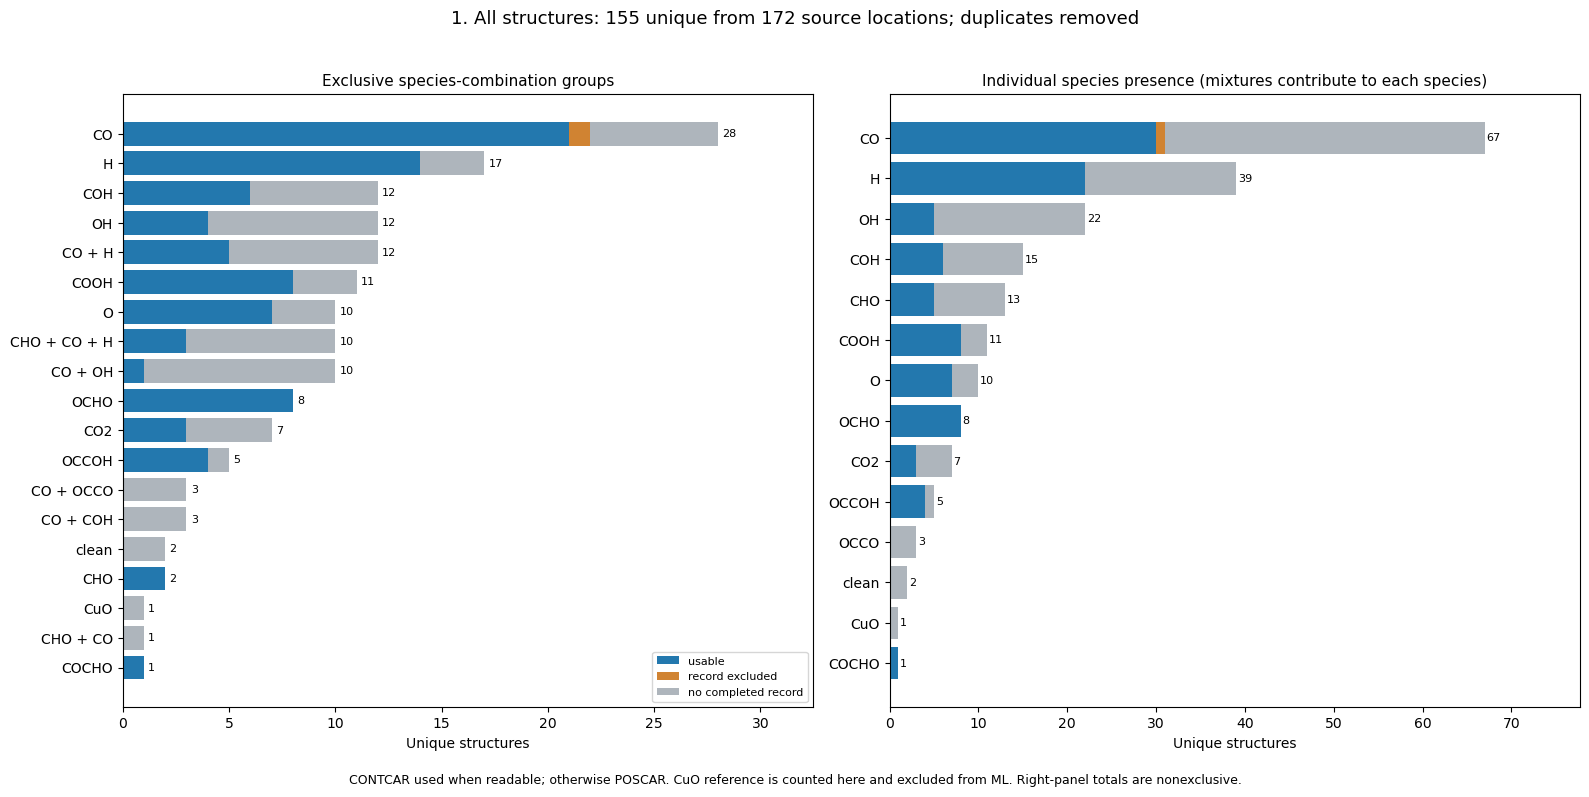

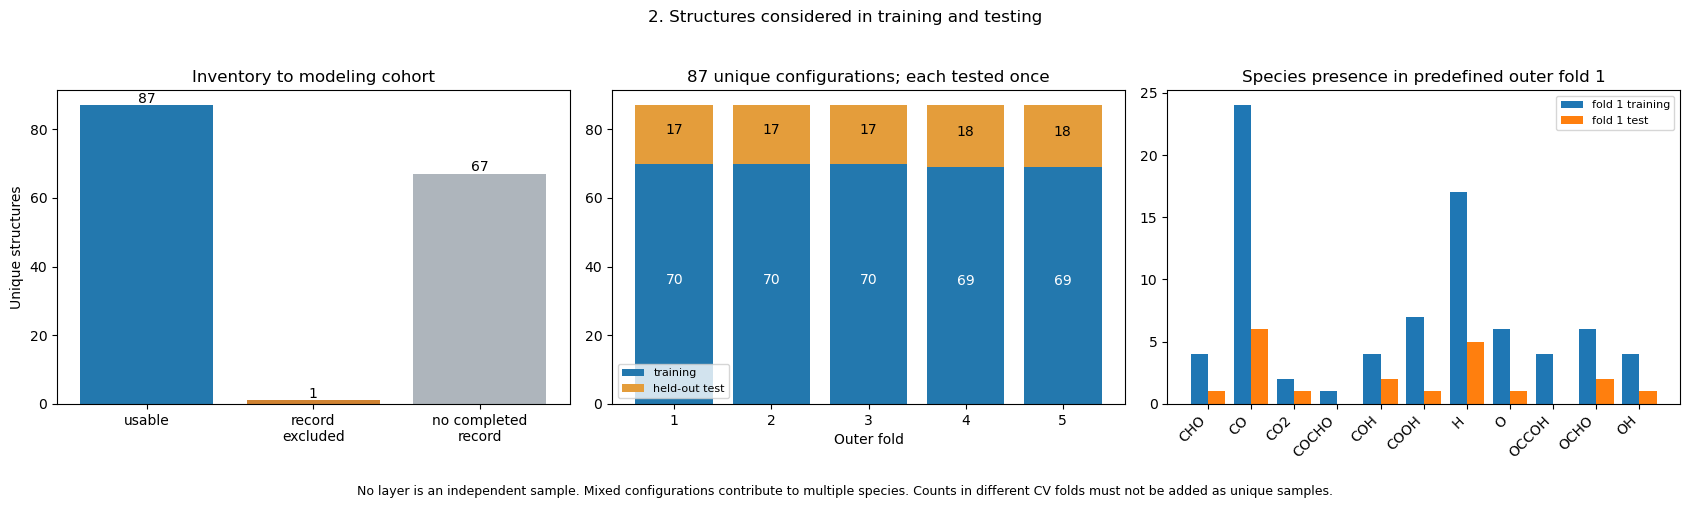

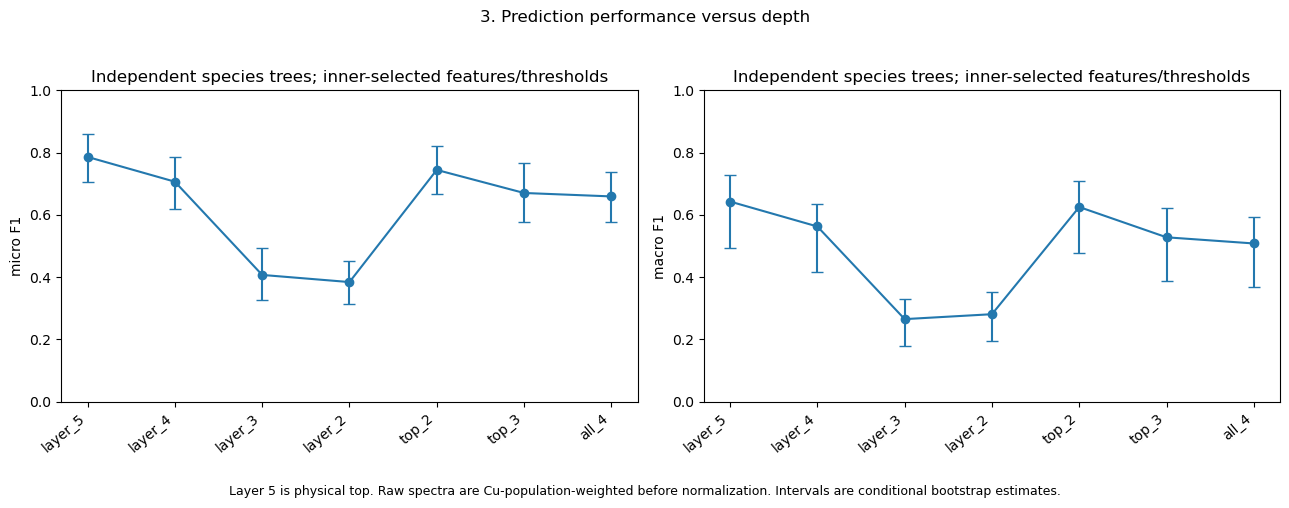

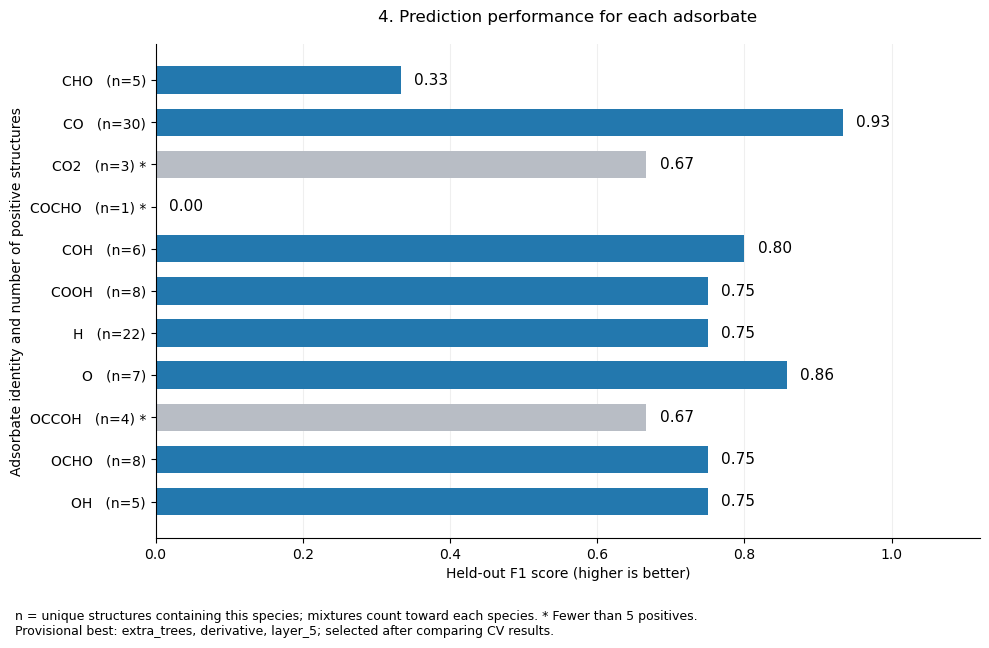

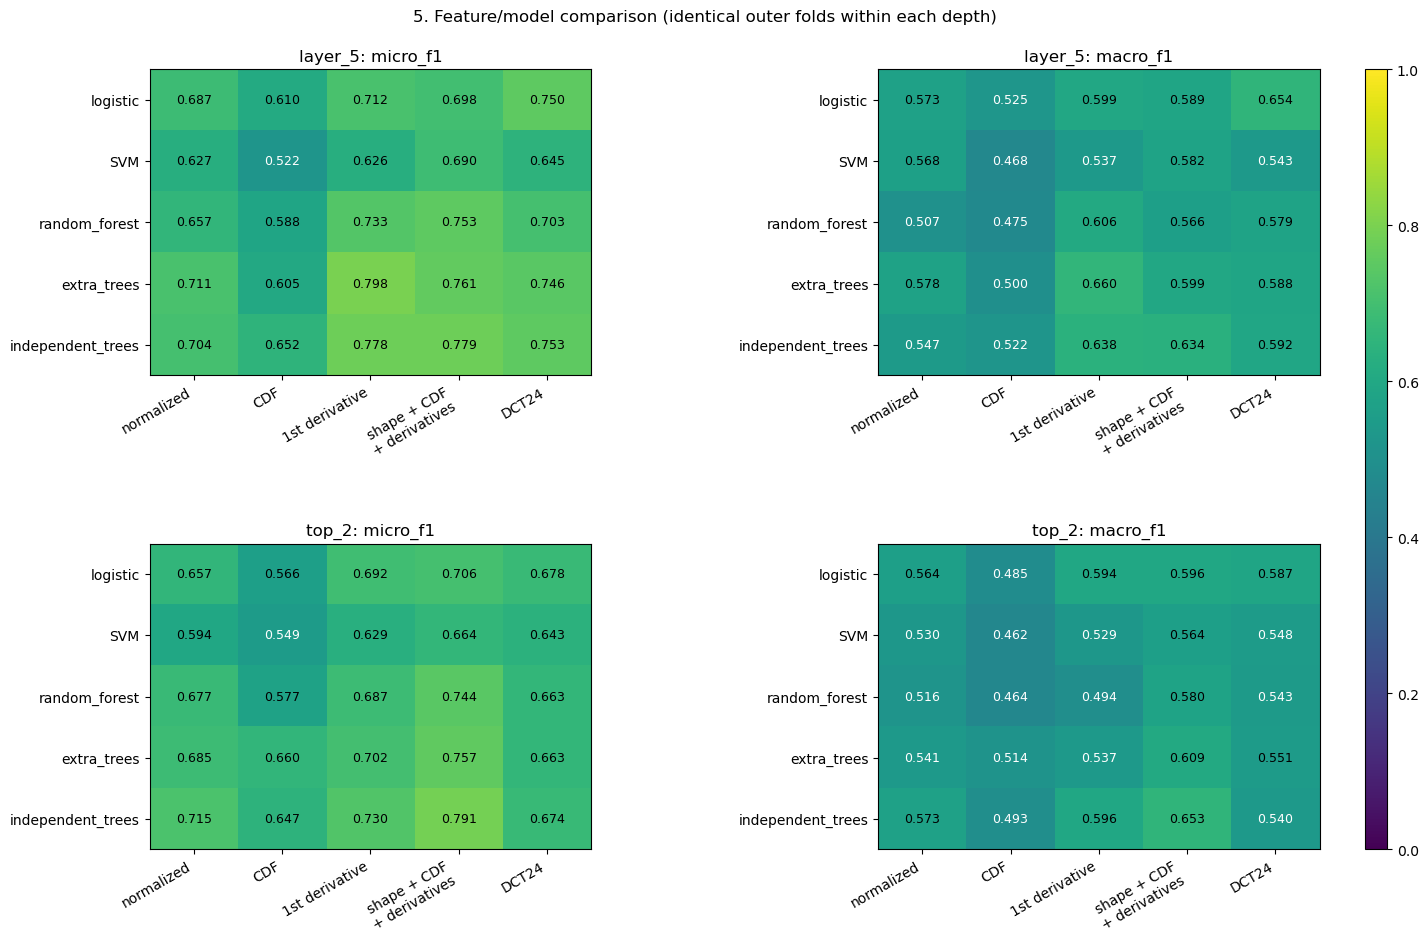

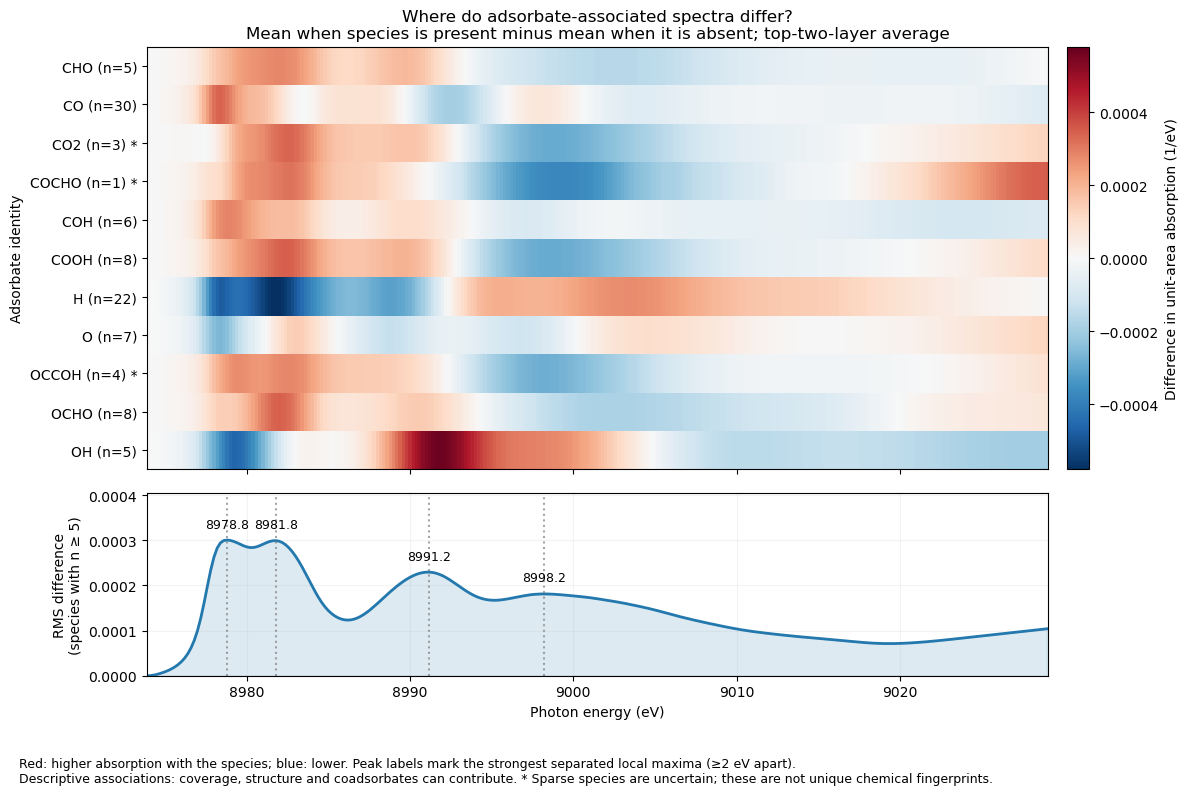

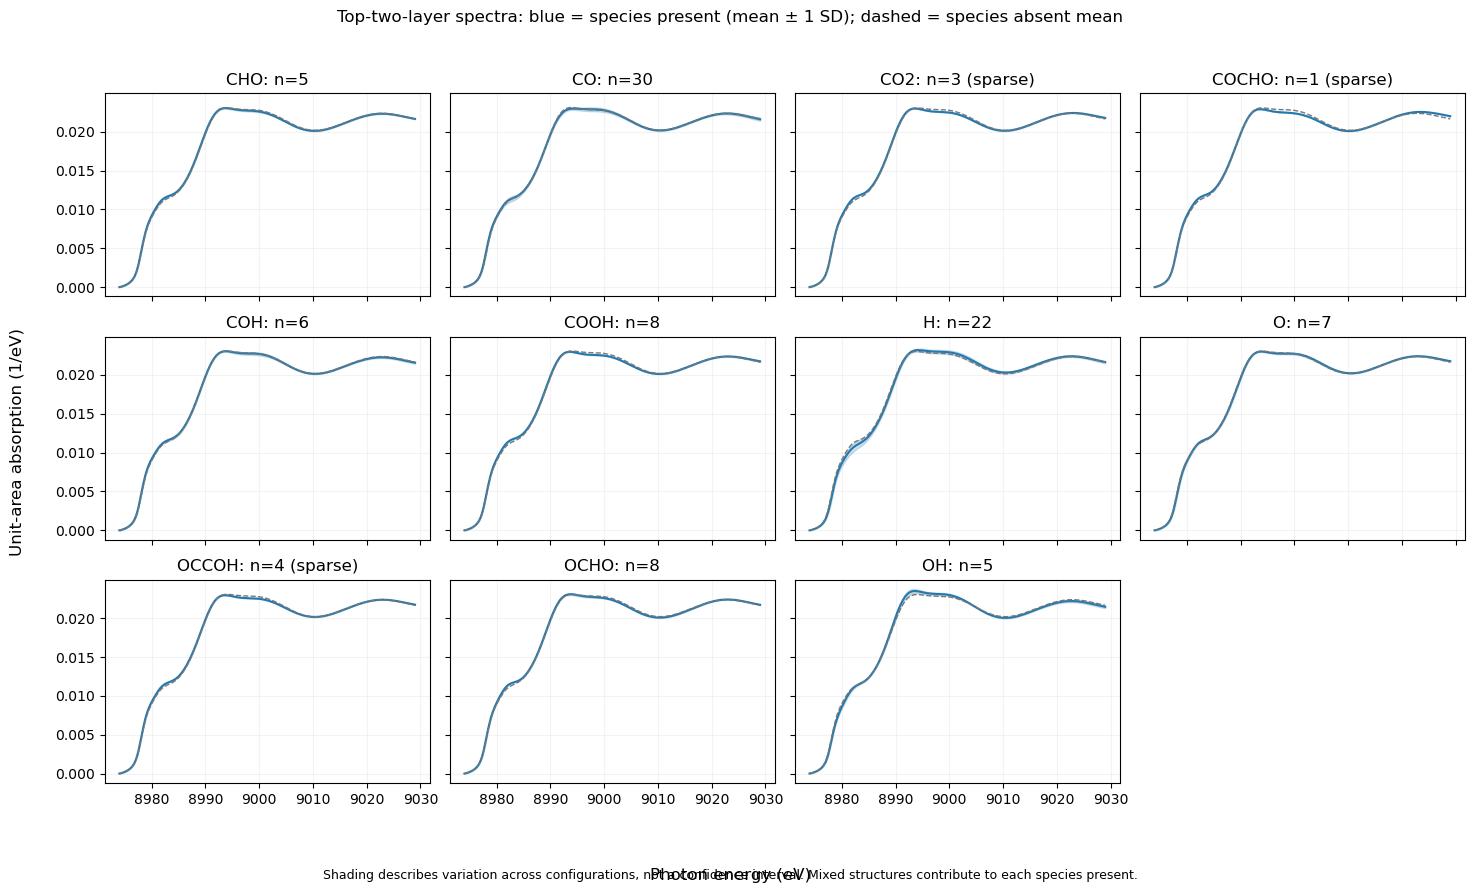

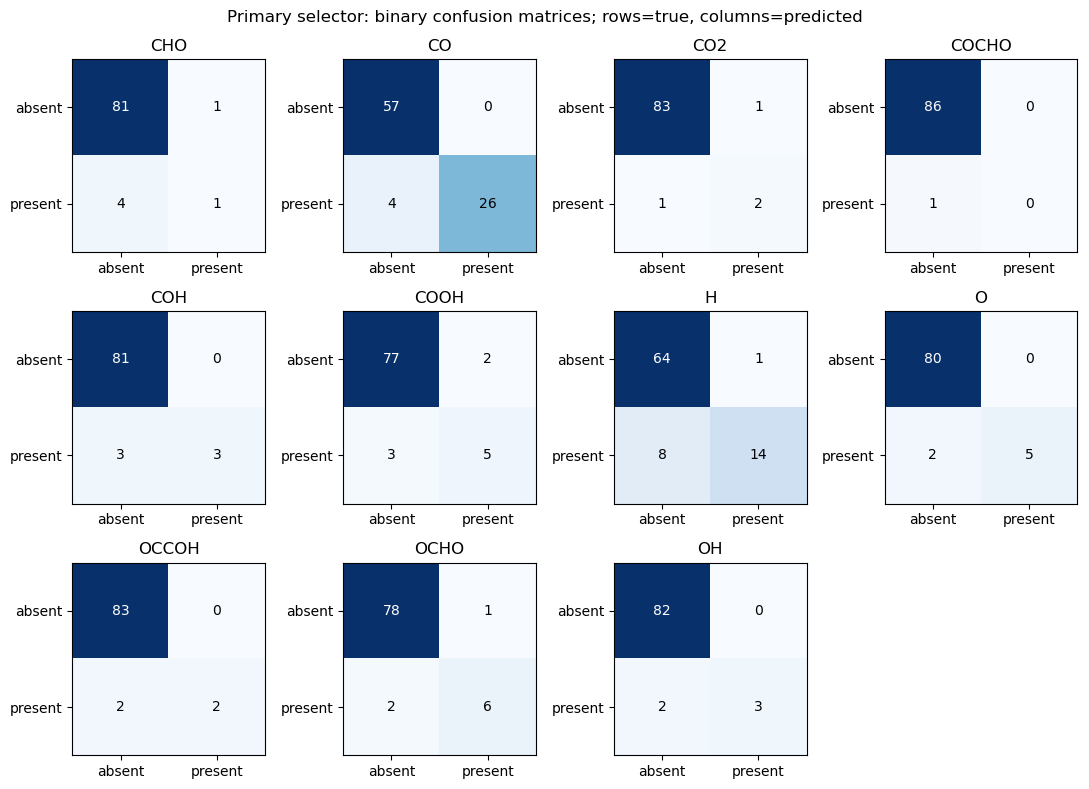

In [7]:
selections=pd.read_csv(OUT/'nested_selections.csv')
selector_predictions={};selector_scores=[];species_rows=[];cm_rows=[]
for (selector,objective),g in selections.groupby(['selector','objective'],sort=False):
    prediction=np.zeros_like(Y);scores=np.zeros(Y.shape,float)
    for r in g.itertuples():
        d=np.load(OUT/f'oof_fold_{r.fold}_{selector}_{objective}.npz');indices=d['indices'];assert np.array_equal(d['truth'],Y[indices]);prediction[indices]=d['prediction'];scores[indices]=d['score']
    selector_predictions[(selector,objective)]=prediction
    np.savez_compressed(OUT/f'oof_{selector}_{objective}.npz',truth=Y,prediction=prediction,score=scores,species=SPECIES,fold=fold_id)
    selector_scores.append(dict(selector=selector,objective=objective,micro_f1=f1_score(Y,prediction,average='micro',zero_division=0),macro_f1=f1_score(Y,prediction,average='macro',zero_division=0),exact_match=np.all(Y==prediction,axis=1).mean()))
    precision,recall,f1,sup=precision_recall_fscore_support(Y,prediction,average=None,zero_division=0)
    for j,label in enumerate(SPECIES):species_rows.append(dict(selector=selector,objective=objective,species=label,precision=precision[j],recall=recall[j],f1=f1[j],support=int(sup[j]),sampling=flags[j]))
    for label,cm in zip(SPECIES,multilabel_confusion_matrix(Y,prediction)):cm_rows.append(dict(selector=selector,objective=objective,species=label,TN=int(cm[0,0]),FP=int(cm[0,1]),FN=int(cm[1,0]),TP=int(cm[1,1])))
selector_scores=pd.DataFrame(selector_scores);species_report=pd.DataFrame(species_rows)
selector_scores.to_csv(OUT/'nested_performance.csv',index=False);species_report.to_csv(OUT/'per_species.csv',index=False);pd.DataFrame(cm_rows).to_csv(OUT/'confusion_matrices.csv',index=False)
# Pooled predictions for every fixed feature/model/depth combination, with threshold selection inside training.
fixed_rows=[];fixed_predictions={}
for spec in CANDIDATES:
    for objective in ['micro','macro']:
        prediction=np.zeros_like(Y)
        for f,(tr,te) in enumerate(FOLDS):
            z=np.load(CACHE/f'{TAG}_{f}_{spec["id"]}.npz');q,t,decoder=threshold_fit(Y[tr],z['inner_score'],objective,False);prediction[te]=z['test_score']>=t
        fixed_predictions[(spec['id'],objective)]=prediction
        fixed_rows.append(dict(**spec,objective=objective,micro_f1=f1_score(Y,prediction,average='micro',zero_division=0),macro_f1=f1_score(Y,prediction,average='macro',zero_division=0)))
fixed_report=pd.DataFrame(fixed_rows);fixed_report.to_csv(OUT/'feature_model_depth_performance.csv',index=False)
best_observed=fixed_report[fixed_report.objective=='micro'].sort_values(['micro_f1','macro_f1'],ascending=False).iloc[0]
chosen=fixed_predictions[(int(best_observed.id),'micro')]
cp,cr,cf,cs=precision_recall_fscore_support(Y,chosen,average=None,zero_division=0)
chosen_species=pd.DataFrame(dict(species=SPECIES,precision=cp,recall=cr,f1=cf,support=cs,sampling=flags))
chosen_species.to_csv(OUT/'provisional_best_per_species.csv',index=False)
chosen_scores=np.zeros(Y.shape,float);chosen_thresholds=np.zeros(Y.shape,float)
for f,(tr,te) in enumerate(FOLDS):
    zz=np.load(CACHE/f'{TAG}_{f}_{int(best_observed.id)}.npz');_,tt,_=threshold_fit(Y[tr],zz['inner_score'],'micro',False);chosen_scores[te]=zz['test_score'];chosen_thresholds[te]=tt
np.savez_compressed(OUT/'oof_provisional_best.npz',truth=Y,prediction=chosen,score=chosen_scores,threshold=chosen_thresholds,species=SPECIES,fold=fold_id)
(OUT/'provisional_best_model.json').write_text(json.dumps(dict(model=str(best_observed.model),feature=str(best_observed.feature),depth=str(best_observed.depth),id=int(best_observed.id),micro_f1=float(best_observed.micro_f1),macro_f1=float(best_observed.macro_f1),selection_status='best observed fixed entry; exploratory selection after CV comparison'),indent=2))
print('Provisional best observed configuration (exploratory):');display(best_observed.to_frame().T);display(chosen_species.round(3))
primary=selector_predictions[('independent_selected','micro')]
primary_result=selector_scores[(selector_scores.selector=='independent_selected')&(selector_scores.objective=='micro')].iloc[0]
primary_species=species_report[(species_report.selector=='independent_selected')&(species_report.objective=='micro')].copy()
print('Predeclared primary independent-species selector:');display(primary_result.to_frame().T);display(primary_species.round(3))
print('Model-family comparisons (family chosen after outer evaluation is exploratory):')
display(selector_scores[selector_scores.selector.str.startswith('model_')].round(3))
# Add completed/usable status to the inventory via alias groups.
usable_configs={s['configuration'] for s in samples}
unique_inventory['ml_status']=['usable' if any(c in usable_configs for c in json.loads(r.aliases)) else ('record excluded' if r.has_record else 'no completed record') for r in unique_inventory.itertuples()]
# If the usable representative was spectrally deduplicated, do not count it twice.
assert (unique_inventory.ml_status=='usable').sum()==N
unique_inventory.to_csv(OUT/'all_unique_structures.csv',index=False)
def save_figure(fig,name):
    fig.savefig(FIG/(name+'.png'),dpi=190,bbox_inches='tight');fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight');plt.show()
COLORS={'usable':'#2378ae','record excluded':'#d08332','no completed record':'#aeb5bc'}
# 1: exclusive exact species combinations and nonexclusive individual species presence.
combo_table=pd.crosstab(unique_inventory.combo,unique_inventory.ml_status).reindex(columns=COLORS,fill_value=0)
combo_table=combo_table.loc[combo_table.sum(axis=1).sort_values().index];combo_table.to_csv(OUT/'figure1_combination_counts.csv')
all_species=sorted({s for labs in unique_inventory.labels for s in labs.split(';')})
presence=pd.DataFrame(0,index=all_species,columns=list(COLORS))
for r in unique_inventory.itertuples():
    for s in r.labels.split(';'):presence.loc[s,r.ml_status]+=1
presence=presence.loc[presence.sum(axis=1).sort_values().index];presence.to_csv(OUT/'figure1_species_presence.csv')
fig,axes=plt.subplots(1,2,figsize=(16,8))
for ax,table,title in zip(axes,[combo_table,presence],['Exclusive species-combination groups','Individual species presence (mixtures contribute to each species)']):
    left=np.zeros(len(table))
    for status in COLORS:ax.barh(table.index,table[status],left=left,label=status,color=COLORS[status]);left+=table[status].to_numpy()
    for i,n in enumerate(left):ax.text(n+.2,i,str(int(n)),va='center',fontsize=8)
    ax.set_xlabel('Unique structures');ax.set_title(title,fontsize=11);ax.set_xlim(0,max(left)*1.16)
axes[0].legend(fontsize=8,loc='lower right');fig.suptitle(f'1. All structures: {len(unique_inventory)} unique from {len(inventory)} source locations; duplicates removed',fontsize=13)
fig.text(.5,.012,'CONTCAR used when readable; otherwise POSCAR. CuO reference is counted here and excluded from ML. Right-panel totals are nonexclusive.',ha='center',fontsize=9)
plt.tight_layout(rect=[0,.035,1,.96]);save_figure(fig,'01_all_structures_by_adsorbate')
# 2: eligibility and actual train/test membership.
fig,axes=plt.subplots(1,3,figsize=(17,5))
status_count=unique_inventory.ml_status.value_counts().reindex(COLORS,fill_value=0)
axes[0].bar(range(3),status_count,color=list(COLORS.values()));axes[0].set_xticks(range(3),['usable','record\nexcluded','no completed\nrecord']);axes[0].set_ylabel('Unique structures');axes[0].set_title('Inventory to modeling cohort')
for i,n in enumerate(status_count):axes[0].text(i,n+.8,str(n),ha='center')
train_counts=[len(tr) for tr,te in FOLDS];test_counts=[len(te) for tr,te in FOLDS]
axes[1].bar(range(1,6),train_counts,label='training',color='#2378ae');axes[1].bar(range(1,6),test_counts,bottom=train_counts,label='held-out test',color='#e49d3b')
for f,(a,b) in enumerate(zip(train_counts,test_counts),1):axes[1].text(f,a/2,str(a),ha='center',color='white');axes[1].text(f,a+b/2,str(b),ha='center')
axes[1].set_xlabel('Outer fold');axes[1].set_title(f'{N} unique configurations; each tested once');axes[1].legend(fontsize=8)
tr,te=FOLDS[0];x=np.arange(len(SPECIES));axes[2].bar(x-.2,Y[tr].sum(axis=0),.4,label='fold 1 training');axes[2].bar(x+.2,Y[te].sum(axis=0),.4,label='fold 1 test');axes[2].set_xticks(x,SPECIES,rotation=45,ha='right');axes[2].set_title('Species presence in predefined outer fold 1');axes[2].legend(fontsize=8)
fig.suptitle('2. Structures considered in training and testing');fig.text(.5,.01,'No layer is an independent sample. Mixed configurations contribute to multiple species. Counts in different CV folds must not be added as unique samples.',ha='center',fontsize=9)
plt.tight_layout(rect=[0,.05,1,.95]);save_figure(fig,'02_training_testing_structure_counts')
pd.DataFrame(dict(fold=np.arange(1,6),training=train_counts,test=test_counts)).to_csv(OUT/'fold_counts.csv',index=False)
# Shared conditional bootstrap resamples of held-out configurations.
rng=np.random.default_rng(SEED);boot=rng.integers(0,N,size=(1500,N))
def bootstrap_f1(pred,metric):
    tp=((Y==1)&(pred==1)).astype(int)[boot].sum(axis=1);fp=((Y==0)&(pred==1)).astype(int)[boot].sum(axis=1);fn=((Y==1)&(pred==0)).astype(int)[boot].sum(axis=1);den=2*tp+fp+fn
    if metric=='macro':return np.divide(2*tp,den,out=np.zeros_like(tp,float),where=den>0).mean(axis=1)
    den=den.sum(axis=1);return np.divide(2*tp.sum(axis=1),den,out=np.zeros(len(den)),where=den>0)
# 3: each individual layer and population-weighted layer average, same configurations/folds.
fig,axes=plt.subplots(1,2,figsize=(13,5));depth_rows=[]
for ax,metric in zip(axes,['micro','macro']):
    value=[];low=[];high=[]
    for depth in DEPTHS:
        pred=selector_predictions[('depth_'+depth,'micro')];score=f1_score(Y,pred,average=metric,zero_division=0);lo,hi=np.quantile(bootstrap_f1(pred,metric),[.025,.975]);value.append(score);low.append(lo);high.append(hi)
        depth_rows.append(dict(depth=depth,metric=metric,f1=score,ci_low=lo,ci_high=hi))
    xx=np.arange(len(DEPTHS));ax.errorbar(xx,value,yerr=[np.array(value)-low,np.array(high)-value],marker='o',capsize=4,color='#2378ae');ax.set_xticks(xx,DEPTHS,rotation=40,ha='right');ax.set_ylim(0,1);ax.set_ylabel(metric+' F1');ax.set_title('Independent species trees; inner-selected features/thresholds')
fig.suptitle('3. Prediction performance versus depth');fig.text(.5,.01,'Layer 5 is physical top. Raw spectra are Cu-population-weighted before normalization. Intervals are conditional bootstrap estimates.',ha='center',fontsize=9)
plt.tight_layout(rect=[0,.06,1,.95]);save_figure(fig,'03_layer_sensitivity');pd.DataFrame(depth_rows).to_csv(OUT/'layer_sensitivity.csv',index=False)
# Paired top-versus-average differences avoid comparing unrelated error bars.
paired=[]
for depth in ['layer_4','layer_3','layer_2','top_2','top_3','all_4']:
    for metric in ['micro','macro']:
        a=selector_predictions[('depth_layer_5','micro')];b=selector_predictions[('depth_'+depth,'micro')];diff=f1_score(Y,a,average=metric,zero_division=0)-f1_score(Y,b,average=metric,zero_division=0);lo,hi=np.quantile(bootstrap_f1(a,metric)-bootstrap_f1(b,metric),[.025,.975]);paired.append(dict(comparison='layer_5 minus '+depth,metric=metric,delta=diff,ci_low=lo,ci_high=hi))
pd.DataFrame(paired).to_csv(OUT/'paired_depth_comparisons.csv',index=False)
# 4: simple per-species held-out F1 with independent configuration counts.
p=chosen_species.set_index('species').loc[SPECIES]
fig,ax=plt.subplots(figsize=(10,6.5));yy=np.arange(len(SPECIES))
ax.barh(yy,p.f1,color=['#b8bdc5' if n<5 else '#2378ae' for n in support],height=.65)
ax.set_yticks(yy,[f'{label}   (n={int(n)})'+(' *' if n<5 else '') for label,n in zip(SPECIES,support)])
for i,value in enumerate(p.f1):ax.text(value+.018,i,f'{value:.2f}',va='center',fontsize=11)
ax.invert_yaxis();ax.set_xlim(0,1.12);ax.set_xticks(np.arange(0,1.01,.2));ax.set_xlabel('Held-out F1 score (higher is better)');ax.set_ylabel('Adsorbate identity and number of positive structures')
ax.set_title('4. Prediction performance for each adsorbate',pad=16)
ax.spines[['top','right']].set_visible(False);ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.text(.02,.015,'n = unique structures containing this species; mixtures count toward each species. * Fewer than 5 positives.\nProvisional best: '+str(best_observed.model)+', '+str(best_observed.feature)+', '+str(best_observed.depth)+'; selected after comparing CV results.',fontsize=9)
plt.tight_layout(rect=[0,.075,1,1]);save_figure(fig,'04_adsorbate_identity_performance')
mixture_rows=[]
for j,label in enumerate(SPECIES):
    for kind,mask in [('single-species',(Y[:,j]==1)&(Y.sum(axis=1)==1)),('mixed',(Y[:,j]==1)&(Y.sum(axis=1)>1))]:
        n=int(mask.sum());detected=int(chosen[mask,j].sum());mixture_rows.append(dict(species=label,kind=kind,support=n,detected=detected,recall=detected/n if n else np.nan))
mixture_report=pd.DataFrame(mixture_rows);mixture_report.to_csv(OUT/'pure_mixed_recall.csv',index=False)
# 5: fair fixed-top-layer feature/model comparison, each threshold selected on training data.
fig,axes=plt.subplots(2,2,figsize=(15,10));features_order=list(BANK['layer_5'])
for row,depth in enumerate(['layer_5','top_2']):
    top=fixed_report[(fixed_report.depth==depth)&(fixed_report.objective=='micro')]
    for ax,metric in zip(axes[row],['micro_f1','macro_f1']):
        table=top.pivot(index='model',columns='feature',values=metric).reindex(index=MODELS,columns=features_order);im=ax.imshow(table.to_numpy(),vmin=0,vmax=1,cmap='viridis',aspect='auto');ax.set_xticks(range(len(features_order)),['normalized','CDF','1st derivative','shape + CDF\n+ derivatives','DCT24'],rotation=30,ha='right');ax.set_yticks(range(len(MODELS)),MODELS);ax.set_title(depth+': '+metric)
        for (i,j),v in np.ndenumerate(table.to_numpy()):ax.text(j,i,f'{v:.3f}',ha='center',va='center',color='white' if v<.55 else 'black',fontsize=9)
fig.subplots_adjust(left=.13,right=.91,wspace=.65,hspace=.55,bottom=.14,top=.92);cax=fig.add_axes([.94,.14,.015,.78]);fig.colorbar(im,cax=cax);fig.suptitle('5. Feature/model comparison (identical outer folds within each depth)');save_figure(fig,'05_feature_model_comparison')
fixed_report[(fixed_report.depth=='layer_5')&(fixed_report.objective=='micro')].to_csv(OUT/'figure5_top_layer_feature_model.csv',index=False)
fixed_report[fixed_report.depth.isin(['layer_5','top_2'])&(fixed_report.objective=='micro')].to_csv(OUT/'figure5_layer5_top2_feature_model.csv',index=False)
# Supplemental energy-resolved identity differences: no crowded line overlays.
# Descriptive cohort contrasts, not a held-out feature selection step.
from scipy.signal import find_peaks
spectra=BANK['top_2']['normalized']
contrast=np.array([spectra[Y[:,j]==1].mean(axis=0)-spectra[Y[:,j]==0].mean(axis=0) for j in range(len(SPECIES))])
# A common physical scale preserves contrast magnitudes across species.
limit=np.max(np.abs(contrast));strength=np.sqrt(np.mean(contrast[support>=5]**2,axis=0))
peaks,_=find_peaks(strength,distance=max(1,int(round(2./np.median(np.diff(energy))))))
peaks=sorted(sorted(peaks,key=lambda k:strength[k],reverse=True)[:5])
peak_rows=[]
for k in peaks:
    largest=np.argsort(np.abs(contrast[:,k]))[::-1][:3]
    peak_rows.append(dict(energy_eV=float(energy[k]),rms_contrast=float(strength[k]),largest_observed_species_contrasts='; '.join(SPECIES[j] for j in largest)))
pd.DataFrame(peak_rows).to_csv(OUT/'spectral_difference_peaks.csv',index=False)
pd.DataFrame(contrast.T,index=pd.Index(energy,name='energy_eV'),columns=SPECIES).to_csv(OUT/'spectral_identity_contrasts.csv')
fig,(ax,lower)=plt.subplots(2,1,figsize=(12,8),sharex=True,gridspec_kw={'height_ratios':[3,1.3]})
im=ax.pcolormesh(energy,np.arange(len(SPECIES)),contrast,cmap='RdBu_r',vmin=-limit,vmax=limit,shading='auto')
ax.set_yticks(range(len(SPECIES)),[f'{label} (n={int(n)})'+(' *' if n<5 else '') for label,n in zip(SPECIES,support)]);ax.invert_yaxis();ax.set_ylabel('Adsorbate identity');ax.set_title('Where do adsorbate-associated spectra differ?\nMean when species is present minus mean when it is absent; top-two-layer average')
fig.colorbar(im,cax=ax.inset_axes([1.02,0,.025,1]),label='Difference in unit-area absorption (1/eV)')
lower.plot(energy,strength,color='#2378ae',lw=2);lower.fill_between(energy,0,strength,color='#2378ae',alpha=.15)
for k in peaks:
    lower.axvline(energy[k],color='gray',ls=':',alpha=.7);lower.annotate(f'{energy[k]:.1f}',(energy[k],strength[k]),xytext=(0,9),textcoords='offset points',ha='center',fontsize=9)
lower.set_ylim(0,strength.max()*1.35);lower.set_ylabel('RMS difference\n(species with n ≥ 5)');lower.set_xlabel('Photon energy (eV)');lower.grid(alpha=.15)
fig.text(.02,.015,'Red: higher absorption with the species; blue: lower. Peak labels mark the strongest separated local maxima (≥2 eV apart).\nDescriptive associations: coverage, structure and coadsorbates can contribute. * Sparse species are uncertain; these are not unique chemical fingerprints.',fontsize=9)
plt.tight_layout(rect=[0,.075,1,1]);save_figure(fig,'supplement_spectral_overlays')
# Individual spectra summarized as species mean and configuration variability.
fig,axes=plt.subplots(3,4,figsize=(15,9),sharex=True,sharey=True)
for j,(ax,label) in enumerate(zip(axes.flat,SPECIES)):
    group=spectra[Y[:,j]==1];mean=group.mean(axis=0);std=group.std(axis=0)
    ax.fill_between(energy,mean-std,mean+std,color='#2378ae',alpha=.22);ax.plot(energy,mean,color='#2378ae',lw=1.5)
    ax.plot(energy,spectra[Y[:,j]==0].mean(axis=0),color='#777777',ls='--',lw=1)
    ax.set_title(f'{label}: n={len(group)}'+(' (sparse)' if len(group)<5 else ''));ax.grid(alpha=.15)
for ax in list(axes.flat)[len(SPECIES):]:ax.axis('off')
fig.supxlabel('Photon energy (eV)');fig.supylabel('Unit-area absorption (1/eV)');fig.suptitle('Top-two-layer spectra: blue = species present (mean ± 1 SD); dashed = species absent mean')
fig.text(.5,.015,'Shading describes variation across configurations, not a confidence interval. Mixed structures contribute to each species present.',ha='center',fontsize=9)
plt.tight_layout(rect=[.02,.045,1,.96]);save_figure(fig,'supplement_species_spectral_summary')
fig,axes=plt.subplots(int(np.ceil(len(SPECIES)/4)),4,figsize=(11,8))
for ax,label,cm in zip(axes.flat,SPECIES,multilabel_confusion_matrix(Y,primary)):
    ax.imshow(cm,cmap='Blues');ax.set_title(label);ax.set_xticks([0,1],['absent','present']);ax.set_yticks([0,1],['absent','present'])
    for (a,b),v in np.ndenumerate(cm):ax.text(b,a,str(v),ha='center',va='center',color='white' if v>cm.max()/2 else 'black')
for ax in list(axes.flat)[len(SPECIES):]:ax.axis('off')
fig.suptitle('Primary selector: binary confusion matrices; rows=true, columns=predicted');plt.tight_layout();save_figure(fig,'supplement_confusion_matrices')


## Simple bullet-point interpretation and checks
The interpretation below is generated from the executed results, including what was tried, the primary workflow, observed rankings, why results remain limited and how to improve the data. It also verifies record/fold uniqueness and that every requested figure was saved.

In [8]:
errors=[]
for i,(a,b) in enumerate(zip(Y,primary)):
    missing=list(SPECIES[(a==1)&(b==0)]);extra=list(SPECIES[(a==0)&(b==1)])
    if missing or extra:errors.append(dict(configuration=manifest.configuration[i],fold=int(fold_id[i]),truth=';'.join(SPECIES[a==1]),prediction=';'.join(SPECIES[b==1]) or '(below thresholds)',missing=';'.join(missing),extra=';'.join(extra)))
pd.DataFrame(errors,columns=['configuration','fold','truth','prediction','missing','extra']).to_csv(OUT/'heldout_errors.csv',index=False)
primary_choices=selections[(selections.selector=='independent_selected')&(selections.objective=='micro')]
family_results=selector_scores[(selector_scores.selector.str.startswith('model_'))&(selector_scores.objective=='micro')]
best_family=family_results.sort_values(['micro_f1','macro_f1'],ascending=False).iloc[0]
best_observed=fixed_report[fixed_report.objective=='micro'].sort_values(['micro_f1','macro_f1'],ascending=False).iloc[0]
rare=', '.join(support_table.loc[support_table.sampling=='INSUFFICIENT','species'])
counts=dict(source_locations=len(inventory),unique_inventory=len(unique_inventory),record_files=len(record_paths),usable=N,layer_spectra=4*N,old_configurations=N-len(new),new_valid_configurations=len(new),duplicate_records=int((record_audit.status=='duplicate').sum()),excluded_records=int((record_audit.status=='excluded').sum()))
(OUT/'run_summary.json').write_text(json.dumps(counts|dict(primary_micro_f1=float(primary_result.micro_f1),primary_macro_f1=float(primary_result.macro_f1),provisional_best_micro_f1=float(best_observed.micro_f1),provisional_best_macro_f1=float(best_observed.macro_f1),best_observed_family=str(best_family.selector)),indent=2))
bullets=[
 f'- Data: {len(inventory)} source locations → {len(unique_inventory)} unique structures, including unfinished cases and the CuO reference. {len(record_paths)} record files → {N} usable unique configurations ({4*N} spectra); {N-len(new)} previous configurations retain their folds and {len(new)} new valid configurations are assigned using labels only.',
 '- Record format: use adsorbate_counts/adsorbate_identities and cross-check component formulas/site species against relaxed CONTCAR. POSCAR is separately audited; dissociation is allowed to change species. Seven regenerated records were backed up and corrected before training. No measurement values were changed.',
 '- Mixtures: exact combinations (for example CO + H) are counted once in the inventory. A second panel reports nonexclusive species presence. Classification is multilabel; counts and site geometry are never predictor inputs or prediction targets.',
 '- Features tried: normalized spectral shape, CDF, first derivative, combined shape/CDF/first-and-second derivatives, DCT24; plus multiscale derivatives and separate top-layer/depth-contrast channels for tree workflows.',
 '- Models tried: balanced logistic regression (C=1), RBF SVM (C=3), joint random forest, joint extra-trees, and independent binary extra-trees classifiers. Native forests have 96 trees; independent forests have 64 trees per species. SVM sigmoid scores are not calibrated probabilities.',
 f'- Predeclared reference workflow: independent-species extra-trees with feature/depth and guarded threshold selection inside the training folds; pooled held-out micro F1 {primary_result.micro_f1:.3f}, macro F1 {primary_result.macro_f1:.3f}, exact label-set accuracy {primary_result.exact_match:.3f}. It was specified from the previous experiments before seeing the new test scores.',
 f'- Provisional best to carry forward: {best_observed.model} with {best_observed.feature} on {best_observed.depth}, because it has the strongest observed pooled micro/macro tradeoff ({best_observed.micro_f1:.3f}/{best_observed.macro_f1:.3f}). It is selected after comparing CV entries, so its score is exploratory and needs independent confirmation.',
 f'- Highest observed model-family score: {best_family.selector.replace("model_","")} (micro/macro F1 {best_family.micro_f1:.3f}/{best_family.macro_f1:.3f}). Highest observed fixed entry: {best_observed.model}, {best_observed.feature}, {best_observed.depth} ({best_observed.micro_f1:.3f}/{best_observed.macro_f1:.3f}). These rankings are exploratory; choosing them after viewing held-out scores is not independent confirmation.',
 '- Validation: identical configuration-level outer folds across all representations; three inner folds select thresholds/features/models; all fitted preprocessing stays in training data. No layer from a structure crosses folds. Macro F1 includes every observed species, including rare failures.',
 f'- Main data limitation: {rare} have fewer than five positive configurations. COCHO has only one, leaving no positive training example when it is held out. More models cannot fix that sampling gap.',
 '- Why performance remains limited: few and imbalanced independent configurations, sparse mixtures, configuration-dependent spectra and potentially diluted depth signatures. Wrong-species substitutions and below-threshold omissions are listed separately. These are model/data limitations, not proof of intrinsic spectral indistinguishability.',
 '- Improvement plan: fix the upstream identity/count converter to classify each molecular component rather than copy directory names; add independent rare-species and matched CO/CO+H/CO+OH configurations; complete clean controls and missing layer averages; reserve new data for confirmation; evaluate sensitivity to noise and energy shifts before experimental transfer.',
 '- Interpretation limits: new data and corrected targets change the benchmark. Repeated exploration of this small simulated cohort is not an external test. Bootstrap intervals condition on fitted CV models, omit retraining uncertainty, and are not corrected for multiple comparisons.'
]
for label in ['H','OH','CHO']:
    if label in SPECIES:
        g=mixture_report[mixture_report.species==label]
        text='; '.join(f'{r.kind}: {r.detected}/{r.support}' for r in g.itertuples() if r.support)
        bullets.append(f'- Provisional-best mixture diagnostic for {label}: {text}.')
depth_scores=selector_scores[(selector_scores.objective=='micro')&selector_scores.selector.isin(['depth_layer_5','depth_top_2','depth_all_4'])].set_index('selector')
depth_winner={'depth_layer_5':'The top layer','depth_top_2':'The top-two average','depth_all_4':'The four-layer average'}[depth_scores.micro_f1.idxmax()]
bullets.insert(8,'- Layer sensitivity (within-depth feature/threshold selection): '+ '; '.join(f'{name}: micro/macro F1 {depth_scores.loc[key,"micro_f1"]:.3f}/{depth_scores.loc[key,"macro_f1"]:.3f}' for key,name in [('depth_layer_5','top layer'),('depth_top_2','top two'),('depth_all_4','all four')])+f'. {depth_winner} has the highest point estimate among these depths. Conditional paired intervals are saved separately.')
chosen_errors=[]
for i,(a,b) in enumerate(zip(Y,chosen)):
    if not np.array_equal(a,b):chosen_errors.append(dict(configuration=manifest.configuration[i],truth=';'.join(SPECIES[a==1]),prediction=';'.join(SPECIES[b==1]) or '(below thresholds)',missing=';'.join(SPECIES[(a==1)&(b==0)]),extra=';'.join(SPECIES[(a==0)&(b==1)])))
pd.DataFrame(chosen_errors).to_csv(OUT/'provisional_best_errors.csv',index=False)
(OUT/'DETAILED_ANALYSIS.md').write_text('\n'.join(bullets)+'\n')
brief=[
 f'- Inventory: **{len(unique_inventory)} unique structures** from {len(inventory)} source locations, including unfinished structures. **{N} configurations / {4*N} spectra** are usable for ML; {len(new)} newly valid configurations were added and the previous folds were preserved.',
 '- Record audit: seven regenerated records had wrong species/counts or site-species labels. They were backed up and corrected from relaxed connectivity; spectra are unchanged. POSCAR/CONTCAR differences are recorded rather than forced to match.',
 '- Population audit corrected: the two recovered CO configurations have 36-site final convolution logs, matching all site files; three-site subset recalculation decks do not determine the final convolution population. No spectra were changed.',
 '- Mixtures: count exact combinations once (CO + H, CHO + CO + H, etc.), and also show per-species presence. Classification stays multilabel; adsorbate multiplicities and geometry are not predicted or used as features.',
 '- Features tried: normalized shape, CDF, first derivative, shape + CDF + both derivatives, DCT24; tree workflows also test multiscale derivatives and top-layer/depth-contrast channels.',
 '- Models tried: logistic regression, RBF SVM, joint random forest, joint extra-trees, and independent species extra-trees. All comparisons use identical outer folds and training-only tuning.',
 f'- Provisional best: **{best_observed.model}, {best_observed.feature}, {best_observed.depth}** — micro F1 **{best_observed.micro_f1:.3f}**, macro F1 **{best_observed.macro_f1:.3f}**. It has the strongest observed score tradeoff, but was chosen after comparing CV entries and needs independent confirmation. The predeclared automatic selector scored {primary_result.micro_f1:.3f}/{primary_result.macro_f1:.3f}.',
 '- Depth: '+ '; '.join(f'{name} {depth_scores.loc[key,"micro_f1"]:.3f}/{depth_scores.loc[key,"macro_f1"]:.3f}' for key,name in [('depth_layer_5','top layer'),('depth_top_2','top two'),('depth_all_4','all four')])+f' (micro/macro F1 with feature selection inside each fixed depth). {depth_winner} has the highest point estimate among these depths; paired uncertainty is reported separately.',
 f'- Why scores remain limited: scarce positives ({rare}), imbalanced data, few mixed examples and configuration-dependent spectral signatures. COCHO has only one example, so its held-out fold has no positive training case. No completed clean controls are available.',
 '- Next steps: fix the upstream component-label converter; add independent rare-species and matched CO/CO+H/CO+OH cases; finish clean controls and repair incomplete/subset layer spectra; reserve new structures for confirmation; test noise/energy-shift robustness.'
]
mixture_notes=[]
for label in ['H','CHO','OH']:
    g=mixture_report[mixture_report.species==label].set_index('kind')
    if 'mixed' in g.index and g.loc['mixed','support']:
        mixture_notes.append(f"{label} {int(g.loc['mixed','detected'])}/{int(g.loc['mixed','support'])} in mixtures")
brief.insert(-1,'- Mixtures remain difficult for the provisional best: '+', '.join(mixture_notes)+'. These omissions limit complete identity-set prediction even when common pure species are detected.')
(OUT/'ANALYSIS.md').write_text('\n'.join(brief)+'\n');display(Markdown('\n'.join(brief)))
# Minimal reproducibility and integrity checks.
assert N==len(set(manifest.structure_hash)) and N==len(set(manifest.record))
assert sorted(np.concatenate([te for tr,te in FOLDS]).tolist())==list(range(N))
for f,(tr,te) in enumerate(FOLDS):
    assert not set(tr)&set(te)
    inner=pd.read_csv(OUT/f'inner_folds_{f}.csv');assert set(inner.manifest_row)==set(tr)
assert int(combo_table.to_numpy().sum())==len(unique_inventory)
assert all((FIG/(name+suffix)).exists() for name in ['01_all_structures_by_adsorbate','02_training_testing_structure_counts','03_layer_sensitivity','04_adsorbate_identity_performance','05_feature_model_comparison'] for suffix in ['.png','.pdf'])
(OUT/'environment.json').write_text(json.dumps(dict(python=sys.version,numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__,seed=SEED),indent=2))
print('Completed. Five requested figures saved as PNG and PDF; full CSV audits and held-out predictions saved alongside the notebook.')


Completed. Five requested figures saved as PNG and PDF; full CSV audits and held-out predictions saved alongside the notebook.


- Inventory: **155 unique structures** from 172 source locations, including unfinished structures. **87 configurations / 348 spectra** are usable for ML; 2 newly valid configurations were added and the previous folds were preserved.
- Record audit: seven regenerated records had wrong species/counts or site-species labels. They were backed up and corrected from relaxed connectivity; spectra are unchanged. POSCAR/CONTCAR differences are recorded rather than forced to match.
- Population audit corrected: the two recovered CO configurations have 36-site final convolution logs, matching all site files; three-site subset recalculation decks do not determine the final convolution population. No spectra were changed.
- Mixtures: count exact combinations once (CO + H, CHO + CO + H, etc.), and also show per-species presence. Classification stays multilabel; adsorbate multiplicities and geometry are not predicted or used as features.
- Features tried: normalized shape, CDF, first derivative, shape + CDF + both derivatives, DCT24; tree workflows also test multiscale derivatives and top-layer/depth-contrast channels.
- Models tried: logistic regression, RBF SVM, joint random forest, joint extra-trees, and independent species extra-trees. All comparisons use identical outer folds and training-only tuning.
- Provisional best: **extra_trees, derivative, layer_5** — micro F1 **0.798**, macro F1 **0.660**. It has the strongest observed score tradeoff, but was chosen after comparing CV entries and needs independent confirmation. The predeclared automatic selector scored 0.779/0.638.
- Depth: top layer 0.786/0.643; top two 0.744/0.625; all four 0.659/0.508 (micro/macro F1 with feature selection inside each fixed depth). The top layer has the highest point estimate among these depths; paired uncertainty is reported separately.
- Why scores remain limited: scarce positives (CO2, COCHO, OCCOH), imbalanced data, few mixed examples and configuration-dependent spectral signatures. COCHO has only one example, so its held-out fold has no positive training case. No completed clean controls are available.
- Mixtures remain difficult for the provisional best: H 1/8 in mixtures, CHO 0/3 in mixtures, OH 0/1 in mixtures. These omissions limit complete identity-set prediction even when common pure species are detected.
- Next steps: fix the upstream component-label converter; add independent rare-species and matched CO/CO+H/CO+OH cases; finish clean controls and repair incomplete/subset layer spectra; reserve new structures for confirmation; test noise/energy-shift robustness.